## Importation des bibliothèques et configuration des chemins 

In [9]:
import os
import re
import sqlite3
import pandas as pd
import pdfplumber

# On remonte d'un niveau si le notebook s'exécute depuis le dossier 'notebooks'
BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()

DOSSIER_CV = os.path.join(BASE_DIR, "data", "cv_pdf")
FICHIER_CSV = os.path.join(BASE_DIR, "data", "dataset_candidats.csv")
FICHIER_EXCEL = os.path.join(BASE_DIR, "data", "dataset_candidats.xlsx")
BDD_SQLITE = os.path.join(BASE_DIR, "recrutement.db")

print(f"📍 Dossier des CVs PDF : {DOSSIER_CV}")

📍 Dossier des CVs PDF : c:\recrutement_ai\data\cv_pdf


## Définition des fonctions de parsing (Extraction d'entités)

In [10]:
def extract_text_from_pdf(pdf_path):
    """Extrait le texte brut d'un fichier PDF."""
    text = ""
    try:
        with pdfplumber.open(pdf_path) as pdf:
            for page in pdf.pages:
                page_text = page.extract_text()
                if page_text:
                    text += page_text + "\n"
    except Exception as e:
        print(f"❌ Erreur sur {os.path.basename(pdf_path)} : {e}")
    return text.strip()

def extract_category(filename):
    """Récupère le métier à partir du nom du fichier."""
    parts = filename.split('_')
    return parts[0] if len(parts) > 1 else "Général"

def extract_identity(text, filename):
    """Estime le Nom / Prénom ou attribue un identifiant."""
    lines = [line.strip() for line in text.split('\n') if line.strip()]
    if lines:
        words = lines[0].split()
        if len(words) >= 2 and len(words[0]) < 20:
            return words[0].capitalize(), " ".join(words[1:]).upper()
    file_id = os.path.splitext(filename)[0]
    return f"Candidat_{file_id}", "Anonyme"

def extract_skills(text):
    """Détecte les compétences clés dans le CV."""
    skills_db = [
        "Python", "SQL", "Machine Learning", "Scikit-Learn", "TensorFlow", 
        "PyTorch", "NLP", "FastAPI", "Flask", "React", "Next.js", "PostgreSQL", 
        "MongoDB", "Docker", "Git", "Power BI", "Excel", "Java", "Spring Boot",
        "C++", "HTML", "CSS", "JavaScript", "Analyse de données", "Deep Learning",
        "Accounting", "Finance", "HR", "Management", "Marketing", "Sales",
        "Gestion de projet", "Communication", "Recrutement", "Audit", "Budget"
    ]
    found = []
    text_lower = text.lower()
    for skill in skills_db:
        if re.search(r'\b' + re.escape(skill.lower()) + r'\b', text_lower):
            found.append(skill)
    return ", ".join(found) if found else "Non spécifiées"

def extract_experience(text):
    """Détermine le niveau d'expérience."""
    text_lower = text.lower()
    exp_pattern = re.search(r'(\d+)\s*(ans|année|années|years|year)\b', text_lower)
    if exp_pattern:
        years = int(exp_pattern.group(1))
        if years < 2: return f"Junior ({years} ans)"
        elif years <= 5: return f"Intermédiaire ({years} ans)"
        else: return f"Sénior ({years} ans)"
    if "senior" in text_lower or "sénior" in text_lower or "lead" in text_lower:
        return "Sénior"
    elif "junior" in text_lower or "intern" in text_lower or "débutant" in text_lower:
        return "Junior"
    return "Non précisé"

def extract_education(text):
    """Détecte les diplômes."""
    text_lower = text.lower()
    degrees = []
    mapping = {
        "Doctorat / PhD": ["doctorat", "phd", "doctorate"],
        "Master / Ingénieur": ["master", "ingénieur", "msc", "bachelor of engineering", "bac+5"],
        "Licence / Bachelor": ["licence", "bachelor", "bs", "bsc", "bac+3"],
        "BTS / DUT / Associate": ["bts", "dut", "associate", "bac+2"]
    }
    for level, kws in mapping.items():
        if any(re.search(r'\b' + re.escape(kw) + r'\b', text_lower) for kw in kws):
            degrees.append(level)
    return ", ".join(degrees) if degrees else "Formation non détectée"

## Exécution de l'extraction & Création du Dataset

In [11]:
fichiers_pdf = [f for f in os.listdir(DOSSIER_CV) if f.lower().endswith('.pdf')]
print(f"🚀 Traitement de {len(fichiers_pdf)} CVs au format PDF...\n")

candidates_list = []

for idx, file_name in enumerate(fichiers_pdf, start=1):
    pdf_path = os.path.join(DOSSIER_CV, file_name)
    raw_text = extract_text_from_pdf(pdf_path)
    
    category = extract_category(file_name)
    prenom, nom = extract_identity(raw_text, file_name)
    competences = extract_skills(raw_text)
    exp = extract_experience(raw_text)
    edu = extract_education(raw_text)
    
    candidates_list.append({
        'Fichier_CV': file_name,
        'Categorie_Poste': category,
        'Prenom': prenom,
        'Nom': nom,
        'Niveau_Experience': exp,
        'Formation': edu,
        'Competences': competences,
        'Texte_Brut': raw_text
    })

df_candidats = pd.DataFrame(candidates_list)

# Exportation des données
os.makedirs(os.path.dirname(FICHIER_CSV), exist_ok=True)
df_candidats.to_csv(FICHIER_CSV, index=False, encoding='utf-8-sig')
df_candidats.to_excel(FICHIER_EXCEL, index=False)

# Sauvegarde SQLite
conn = sqlite3.connect(BDD_SQLITE)
df_candidats.to_sql("candidats", conn, if_exists="replace", index=False)
conn.close()

print("🎉 Extraction terminée et sauvegardée dans 'dataset_candidats.csv' et 'recrutement.db' !")

🚀 Traitement de 240 CVs au format PDF...

🎉 Extraction terminée et sauvegardée dans 'dataset_candidats.csv' et 'recrutement.db' !


C:\Users\T480S\AppData\Local\Temp\ipykernel_12468\1048370830.py:32: UserWarning: Cell contents too long (35115), truncated to 32767 characters
  df_candidats.to_excel(FICHIER_EXCEL, index=False)


### fiches de poste de référence 

In [12]:
import sqlite3
import pandas as pd

# ------------------------------------------------------------------------------
# CONSTITUTION DU DATASET DES OFFRES D'EMPLOI (dataset_offres.csv)
# ------------------------------------------------------------------------------

offres_data = [
    {
        'ID_Offre': 'OFFRE_01',
        'Titre_Poste': 'Data Scientist Senior',
        'Categorie_Metier': 'DATA_SCIENCE',
        'Competences_Exigees': 'Python, Machine Learning, SQL, Scikit-Learn, TensorFlow, NLP, FastAPI',
        'Niveau_Experience_Exige': 'Sénior (3 ans et +)',
        'Formation_Exigee': 'Master / Ingénieur',
        'Description_Brute': """
        Nous recherchons un Data Scientist Senior passionné par la conception et le déploiement 
        de modèles de Machine Learning et de traitement du langage naturel (NLP). 
        Le candidat idéal maîtrise Python, Scikit-Learn, TensorFlow, les requêtes SQL complexes 
        et la création d'API REST avec FastAPI pour l'intégration de solutions IA.
        """
    },
    {
        'ID_Offre': 'OFFRE_02',
        'Titre_Poste': 'Développeur Fullstack Python / React',
        'Categorie_Metier': 'INFORMATION-TECHNOLOGY',
        'Competences_Exigees': 'Python, Flask, FastAPI, React, JavaScript, PostgreSQL, Docker, Git',
        'Niveau_Experience_Exige': 'Intermédiaire (2 à 5 ans)',
        'Formation_Exigee': 'Licence / Bachelor',
        'Description_Brute': """
        Entreprise en forte croissance cherche un Développeur Fullstack. Vous serez en charge 
        du développement des fonctionnalités Backend sous Python (Flask/FastAPI) et Frontend en React. 
        Solides connaissances exigées en bases de données PostgreSQL, conteneurisation Docker et gestion de version Git.
        """
    },
    {
        'ID_Offre': 'OFFRE_03',
        'Titre_Poste': 'Responsable Ressources Humaines & Recrutement',
        'Categorie_Metier': 'HR',
        'Competences_Exigees': 'HR, Recrutement, Communication, Management, Excel',
        'Niveau_Experience_Exige': 'Sénior (5 ans et +)',
        'Formation_Exigee': 'Master / Ingénieur',
        'Description_Brute': """
        Nous recrutons un Responsable RH pour piloter l'ensemble du processus de pré-sélection 
        et d'intégration des talents. Exigence d'une excellente capacité de communication, 
        d'une maîtrise des techniques de recrutement et de la gestion budgétaire sous Excel.
        """
    },
    {
        'ID_Offre': 'OFFRE_04',
        'Titre_Poste': 'Analyste Financier & Comptable',
        'Categorie_Metier': 'FINANCE',
        'Competences_Exigees': 'Finance, Accounting, Audit, Budget, Excel, Power BI',
        'Niveau_Experience_Exige': 'Intermédiaire (2 à 5 ans)',
        'Formation_Exigee': 'Master / Ingénieur',
        'Description_Brute': """
        Poste d'Analyste Financier pour assurer l'élaboration du budget annuel, le suivi comptable 
        et la création de tableaux de bord décisionnels sous Power BI et Excel. Solides compétences 
        en analyse de données financières et audit exigées.
        """
    }
]

df_offres = pd.DataFrame(offres_data)

# 1. Sauvegarde CSV & Excel
FICHIER_OFFRES_CSV = os.path.join(BASE_DIR, "data", "dataset_offres.csv")
df_offres.to_csv(FICHIER_OFFRES_CSV, index=False, encoding='utf-8-sig')

# 2. Insérer dans la base de données SQLite (table 'offres')
conn = sqlite3.connect(BDD_SQLITE)
df_offres.to_sql("offres", conn, if_exists="replace", index=False)
conn.close()

print("🎉 Dataset des offres créé avec succès : 'dataset_offres.csv' et table 'offres' dans 'recrutement.db' !")
display(df_offres[['ID_Offre', 'Titre_Poste', 'Categorie_Metier', 'Competences_Exigees', 'Niveau_Experience_Exige']])

🎉 Dataset des offres créé avec succès : 'dataset_offres.csv' et table 'offres' dans 'recrutement.db' !


,ID_Offre,Titre_Poste,Categorie_Metier,Competences_Exigees,Niveau_Experience_Exige
0,OFFRE_01,Data Scientist Senior,DATA_SCIENCE,"Python, Machine Learning, SQL, Scikit-Learn, T...",Sénior (3 ans et +)
1,OFFRE_02,Développeur Fullstack Python / React,INFORMATION-TECHNOLOGY,"Python, Flask, FastAPI, React, JavaScript, Pos...",Intermédiaire (2 à 5 ans)
2,OFFRE_03,Responsable Ressources Humaines & Recrutement,HR,"HR, Recrutement, Communication, Management, Excel",Sénior (5 ans et +)
3,OFFRE_04,Analyste Financier & Comptable,FINANCE,"Finance, Accounting, Audit, Budget, Excel, Pow...",Intermédiaire (2 à 5 ans)


# Inspection & Analyse Descriptive Complète

In [13]:
import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------------------------
# 1. CHARGEMENT DU DATASET
# ------------------------------------------------------------------------------
BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
FICHIER_CSV = os.path.join(BASE_DIR, "data", "dataset_candidats.csv")

if not os.path.exists(FICHIER_CSV):
    FICHIER_CSV = "dataset_candidats.csv"

df = pd.read_csv(FICHIER_CSV)

print("=" * 80)
print("1. STRUCTURE GLOBALE ET DIMENSIONS DU DATASET")
print("=" * 80)
print(f"• Nombre total de lignes (candidats) : {df.shape[0]}")
print(f"• Nombre total de colonnes (variables): {df.shape[1]}")
print(f"• Dimensions (Lignes, Colonnes)      : {df.shape}")

print("\n" + "=" * 80)
print("2. LISTE DES COLONNES ET TYPES DE DONNÉES")
print("=" * 80)
print(df.dtypes)

print("\n" + "=" * 80)
print("3. INFORMATION DÉTAILLÉE SUR LES COLONNES (df.info())")
print("=" * 80)
df.info()

# ------------------------------------------------------------------------------
# 2. AFFICHAGE DE L'ENTÊTE ET DU PIED DE PAGE
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("4. APERÇU DE L'ENTÊTE DU DATASET (df.head(5))")
print("=" * 80)
# Masquage temporaire du texte brut très long pour un affichage lisible
display(df.drop(columns=['Texte_Brut']).head(5))

print("\n" + "=" * 80)
print("5. APERÇU DU PIED DE PAGE (df.tail(5))")
print("=" * 80)
display(df.drop(columns=['Texte_Brut']).tail(5))

# ------------------------------------------------------------------------------
# 3. VALEURS MANQUANTES ET COMPLÉTUDE
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("6. DÉTECTION DES VALEURS MANQUANTES / NULLS")
print("=" * 80)
null_df = pd.DataFrame({
    'Valeurs_Manquantes': df.isnull().sum(),
    'Pourcentage (%)': (df.isnull().sum() / len(df)) * 100
})
display(null_df)

# ------------------------------------------------------------------------------
# 4. STATISTIQUES DES VARIABLES
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("7. STATISTIQUES DES VARIABLES CATÉGORIELLES (df.describe(include='object'))")
print("=" * 80)
display(df.describe(include='object').drop(columns=['Texte_Brut'], errors='ignore'))

# ------------------------------------------------------------------------------
# 5. STATISTIQUES TEXTUELLES SUR LE TEXTE BRUT (VOLUMÉTRIE)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("8. ANALYSE DE VOLUMÉTRIE SUR LE TEXTE BRUT DES CVS")
print("=" * 80)
df['Nb_Caracteres'] = df['Texte_Brut'].astype(str).apply(len)
df['Nb_Mots'] = df['Texte_Brut'].astype(str).apply(lambda x: len(x.split()))

display(df[['Nb_Caracteres', 'Nb_Mots']].describe())

1. STRUCTURE GLOBALE ET DIMENSIONS DU DATASET
• Nombre total de lignes (candidats) : 240
• Nombre total de colonnes (variables): 8
• Dimensions (Lignes, Colonnes)      : (240, 8)

2. LISTE DES COLONNES ET TYPES DE DONNÉES
Fichier_CV           str
Categorie_Poste      str
Prenom               str
Nom                  str
Niveau_Experience    str
Formation            str
Competences          str
Texte_Brut           str
dtype: object

3. INFORMATION DÉTAILLÉE SUR LES COLONNES (df.info())
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Fichier_CV         240 non-null    str  
 1   Categorie_Poste    240 non-null    str  
 2   Prenom             240 non-null    str  
 3   Nom                240 non-null    str  
 4   Niveau_Experience  240 non-null    str  
 5   Formation          240 non-null    str  
 6   Competences        240 non-null    str  
 7

,Fichier_CV,Categorie_Poste,Prenom,Nom,Niveau_Experience,Formation,Competences
0,ACCOUNTANT_11759079.pdf,ACCOUNTANT,Senior,ACCOUNTANT,Sénior,"Licence / Bachelor, BTS / DUT / Associate","Excel, Accounting, Management, Sales, Audit, B..."
1,ACCOUNTANT_13491889.pdf,ACCOUNTANT,Candidat_ACCOUNTANT_13491889,Anonyme,Junior,Formation non détectée,"Excel, Accounting, Finance, HR, Management, Ma..."
2,ACCOUNTANT_13701259.pdf,ACCOUNTANT,Senior,ACCOUNTANT,Sénior,Licence / Bachelor,"Excel, Accounting, Finance, HR, Management, Audit"
3,ACCOUNTANT_14224370.pdf,ACCOUNTANT,Candidat_ACCOUNTANT_14224370,Anonyme,Sénior (10 ans),Licence / Bachelor,"Excel, Accounting, Management, Sales, Communic..."
4,ACCOUNTANT_17306905.pdf,ACCOUNTANT,Senior,ACCOUNTANT,Sénior (15 ans),Licence / Bachelor,"Excel, Accounting, Finance, Management, Sales,..."



5. APERÇU DU PIED DE PAGE (df.tail(5))


,Fichier_CV,Categorie_Poste,Prenom,Nom,Niveau_Experience,Formation,Competences
235,TEACHER_33704389.pdf,TEACHER,Candidat_TEACHER_33704389,Anonyme,Junior,Licence / Bachelor,Communication
236,TEACHER_34465087.pdf,TEACHER,Candidat_TEACHER_34465087,Anonyme,Sénior (15 ans),BTS / DUT / Associate,"Management, Marketing, Sales, Communication"
237,TEACHER_34689720.pdf,TEACHER,Candidat_TEACHER_34689720,Anonyme,Intermédiaire (4 ans),Licence / Bachelor,Management
238,TEACHER_38750659.pdf,TEACHER,Candidat_TEACHER_38750659,Anonyme,Junior,"Master / Ingénieur, Licence / Bachelor","HR, Management, Sales, Communication"
239,TEACHER_79663360.pdf,TEACHER,Substitute,TEACHER,Sénior,"Master / Ingénieur, Licence / Bachelor","Communication, Budget"



6. DÉTECTION DES VALEURS MANQUANTES / NULLS


...


7. STATISTIQUES DES VARIABLES CATÉGORIELLES (df.describe(include='object'))


C:\Users\T480S\AppData\Local\Temp\ipykernel_12468\2579806488.py:65: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object').drop(columns=['Texte_Brut'], errors='ignore'))


,Fichier_CV,Categorie_Poste,Prenom,Nom,Niveau_Experience,Formation,Competences
count,240,240,240,240,240,240,240
unique,240,24,152,150,26,9,139
top,ACCOUNTANT_11759079.pdf,ACCOUNTANT,Senior,Anonyme,Sénior,Formation non détectée,"Management, Communication"
freq,1,10,10,39,108,65,15



8. ANALYSE DE VOLUMÉTRIE SUR LE TEXTE BRUT DES CVS


,Nb_Caracteres,Nb_Mots
count,240.000000,240.000000
mean,5832.008333,803.345833
std,3130.737569,446.879709
min,1130.000000,164.000000
25%,4736.500000,643.500000
50%,5327.500000,738.000000
75%,6675.000000,912.250000
max,35115.000000,5190.000000


# Analyse Exploratoire Complète (EDA & Visualisations)

. Création des variables dérivées pour l'EDA

In [15]:
import os
import pandas as pd
import numpy as np

# Chargement du dataset généré à l'étape précédente
BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
FICHIER_CSV = os.path.join(BASE_DIR, "data", "dataset_candidats.csv")

if not os.path.exists(FICHIER_CSV):
    FICHIER_CSV = "dataset_candidats.csv"

df = pd.read_csv(FICHIER_CSV)

# Calcul des métriques textuelles et d'extraction
df['Longueur_Caracteres'] = df['Texte_Brut'].astype(str).apply(len)
df['Nombre_Mots'] = df['Texte_Brut'].astype(str).apply(lambda x: len(x.split()))
df['Nombre_Competences'] = df['Competences'].astype(str).apply(
    lambda x: len([s for s in x.split(',') if s.strip() not in ["Non spécifiées", ""]])
)

print("✅ Variables dérivées créées : 'Longueur_Caracteres', 'Nombre_Mots', 'Nombre_Competences'")
display(df[['Nombre_Mots', 'Nombre_Competences', 'Longueur_Caracteres']].describe())

✅ Variables dérivées créées : 'Longueur_Caracteres', 'Nombre_Mots', 'Nombre_Competences'


,Nombre_Mots,Nombre_Competences,Longueur_Caracteres
count,240.000000,240.000000,240.000000
mean,803.345833,3.795833,5832.008333
std,446.879709,2.118849,3130.737569
min,164.000000,0.000000,1130.000000
25%,643.500000,2.000000,4736.500000
50%,738.000000,4.000000,5327.500000
75%,912.250000,5.000000,6675.000000
max,5190.000000,11.000000,35115.000000


# Distribution de la longueur des textes (Nombre de mots)

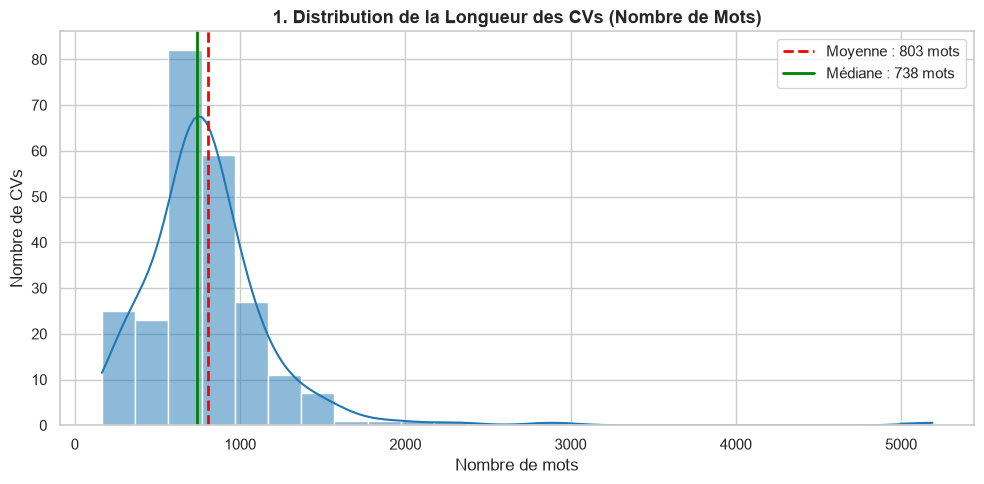

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Plot Histogramme + KDE
ax = sns.histplot(df['Nombre_Mots'], kde=True, color="#1f77b4", bins=25)

mean_val = df['Nombre_Mots'].mean()
median_val = df['Nombre_Mots'].median()

plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Moyenne : {mean_val:.0f} mots')
plt.axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Médiane : {median_val:.0f} mots')

plt.title("1. Distribution de la Longueur des CVs (Nombre de Mots)", fontsize=13, fontweight='bold')
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre de CVs")
plt.legend()
plt.tight_layout()
plt.show()

# Croisement Métier vs Niveau d'Expérience (Heatmap)

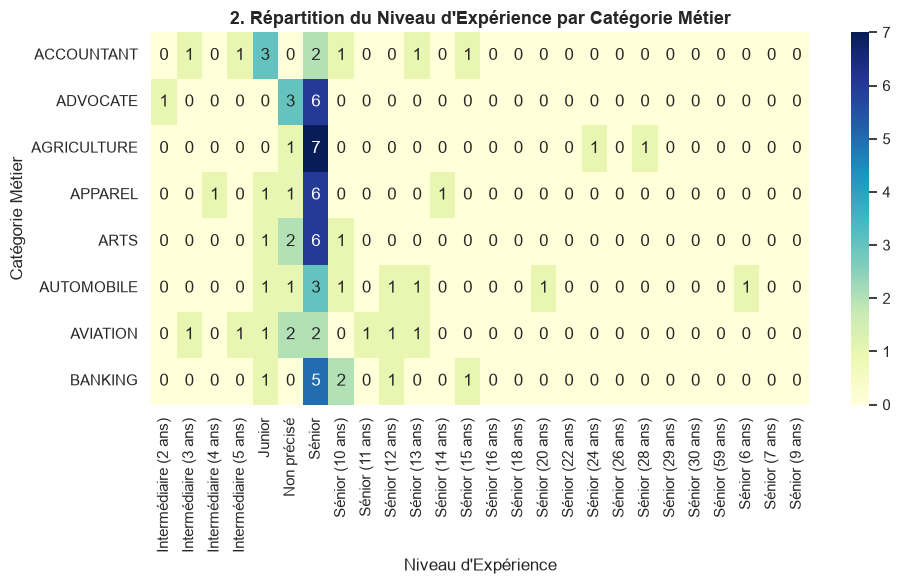

In [17]:
plt.figure(figsize=(10, 6))

# Tableau croisé dynamique entre Categorie_Poste et Niveau_Experience
ct_exp = pd.crosstab(df['Categorie_Poste'], df['Niveau_Experience'])

# Sélection des 8 principales catégories métiers pour un affichage lisible
top_cats = df['Categorie_Poste'].value_counts().head(8).index
ct_exp_top = ct_exp.loc[ct_exp.index.isin(top_cats)]

sns.heatmap(ct_exp_top, annot=True, fmt='d', cmap="YlGnBu", cbar=True)

plt.title("2. Répartition du Niveau d'Expérience par Catégorie Métier", fontsize=13, fontweight='bold')
plt.xlabel("Niveau d'Expérience")
plt.ylabel("Catégorie Métier")
plt.tight_layout()
plt.show()

# Densité des compétences extraites par domaine

C:\Users\T480S\AppData\Local\Temp\ipykernel_12468\1580000736.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Categorie_Poste', y='Nombre_Competences', data=df_top, palette="Set2")


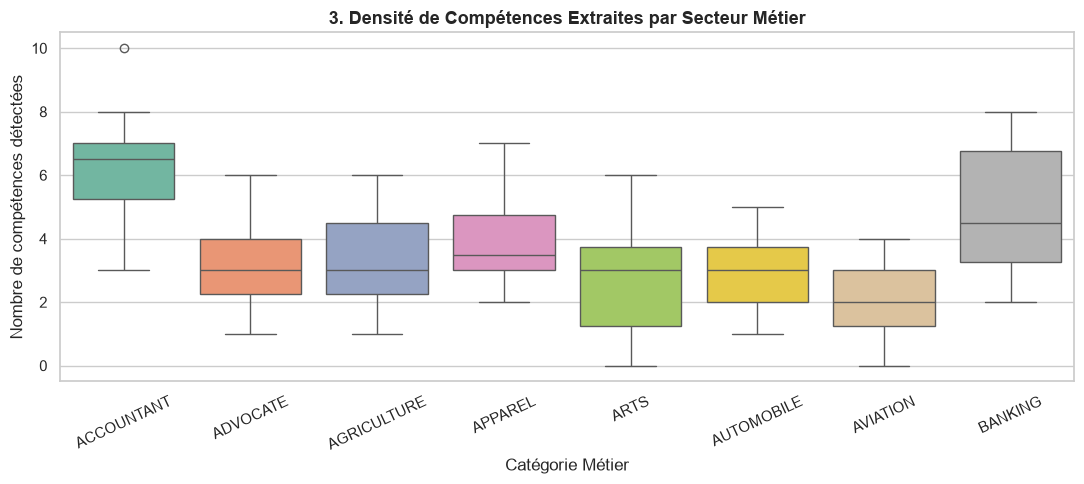

In [18]:
plt.figure(figsize=(11, 5))

top_cats = df['Categorie_Poste'].value_counts().head(8).index
df_top = df[df['Categorie_Poste'].isin(top_cats)]

sns.boxplot(x='Categorie_Poste', y='Nombre_Competences', data=df_top, palette="Set2")

plt.title("3. Densité de Compétences Extraites par Secteur Métier", fontsize=13, fontweight='bold')
plt.xlabel("Catégorie Métier")
plt.ylabel("Nombre de compétences détectées")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Top 15 des compétences les plus fréquentes (NLP EDA)

C:\Users\T480S\AppData\Local\Temp\ipykernel_12468\2140442266.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_15_skills.values, y=top_15_skills.index, palette="mako")


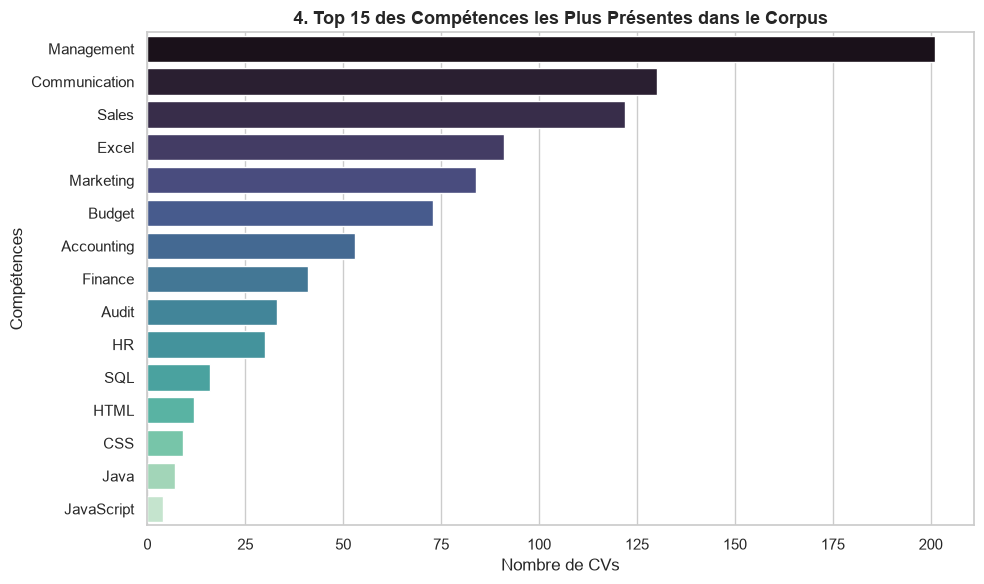

In [19]:
from collections import Counter

plt.figure(figsize=(10, 6))

# Extraction et comptage individuel des compétences
skills_list = []
for item in df['Competences'].dropna():
    for skill in item.split(','):
        cleaned = skill.strip()
        if cleaned and cleaned != "Non spécifiées":
            skills_list.append(cleaned)

top_15_skills = pd.Series(Counter(skills_list)).sort_values(ascending=False).head(15)

sns.barplot(x=top_15_skills.values, y=top_15_skills.index, palette="mako")

plt.title("4. Top 15 des Compétences les Plus Présentes dans le Corpus", fontsize=13, fontweight='bold')
plt.xlabel("Nombre de CVs")
plt.ylabel("Compétences")
plt.tight_layout()
plt.show()

In [20]:
import os
import re
import sqlite3
import pandas as pd

# ------------------------------------------------------------------------------
# 1. CHARGEMENT ET DÉFINITION DU PRÉTRAITEMENT NLP
# ------------------------------------------------------------------------------
BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
BDD_SQLITE = os.path.join(BASE_DIR, "recrutement.db")
FICHIER_CSV = os.path.join(BASE_DIR, "data", "dataset_candidats.csv")

conn = sqlite3.connect(BDD_SQLITE)
df_candidats = pd.read_sql("SELECT * FROM candidats", conn)
conn.close()

# Liste des mots vides (Stopwords FR & EN)
STOPWORDS = set([
    "le", "la", "les", "un", "une", "des", "du", "de", "en", "et", "est", "que", "qui", 
    "dans", "sur", "pour", "avec", "par", "au", "aux", "ce", "ces", "pas", "plus",
    "the", "a", "an", "and", "or", "in", "on", "at", "to", "for", "with", "by", "from",
    "of", "is", "are", "was", "were", "be", "been", "being", "have", "has", "had", "this"
])

def preprocess_text(text):
    if not isinstance(text, str) or not text.strip():
        return ""
    text_clean = text.lower()
    text_clean = re.sub(r'http\S+|www\S+|\S+@\S+', '', text_clean)
    text_clean = re.sub(r'[^a-zàâçéèêëîïôûùüÿñæœa-z]', ' ', text_clean)
    tokens = [w for w in text_clean.split() if w not in STOPWORDS and len(w) > 1]
    return " ".join(tokens)

# ------------------------------------------------------------------------------
# 2. APPLICATION ET RECHARGEMENT DANS SQLITE
# ------------------------------------------------------------------------------
df_candidats['Texte_Nettoye'] = df_candidats['Texte_Brut'].apply(preprocess_text)

# Mise à jour du CSV et de la table 'candidats' dans SQLite
df_candidats.to_csv(FICHIER_CSV, index=False, encoding='utf-8-sig')

conn = sqlite3.connect(BDD_SQLITE)
df_candidats.to_sql("candidats", conn, if_exists="replace", index=False)

# Vérification du nouveau schéma
cursor = conn.cursor()
cursor.execute("PRAGMA table_info(candidats)")
colonnes = [row[1] for row in cursor.fetchall()]
conn.close()

print("✅ Base SQLite mise à jour avec succès !")
print(f"📌 Liste des colonnes désormais présentes dans la table 'candidats' ({len(colonnes)} colonnes) :")
print(colonnes)

✅ Base SQLite mise à jour avec succès !
📌 Liste des colonnes désormais présentes dans la table 'candidats' (9 colonnes) :
['Fichier_CV', 'Categorie_Poste', 'Prenom', 'Nom', 'Niveau_Experience', 'Formation', 'Competences', 'Texte_Brut', 'Texte_Nettoye']


***PHASE 4: Modeling (Moteur de matching sémantique)***

In [21]:
import os
import sqlite3
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# ------------------------------------------------------------------------------
# 1. CHARGEMENT DES DONNÉES DEPUIS SQLITE
# ------------------------------------------------------------------------------
BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
BDD_SQLITE = os.path.join(BASE_DIR, "recrutement.db")

conn = sqlite3.connect(BDD_SQLITE)
df_candidats = pd.read_sql("SELECT * FROM candidats", conn)
df_offres = pd.read_sql("SELECT * FROM offres", conn)
conn.close()

print(f"✅ Donnees chargees : {len(df_candidats)} candidats et {len(df_offres)} offres d'emploi.")

# ------------------------------------------------------------------------------
# 2. CHARGEMENT DU MODÈLE SBERT MULTILINGUE
# ------------------------------------------------------------------------------
print("\n⏳ Chargement du modele Sentence-BERT (paraphrase-multilingual-MiniLM-L12-v2)...")
sbert_model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
print("✅ Modèle Sentence-BERT prêt !")

# ------------------------------------------------------------------------------
# 3. MOTEUR DE MATCHING HYBRIDE (TF-IDF vs SBERT)
# ------------------------------------------------------------------------------
def run_matching_engine(id_offre='OFFRE_01', top_n=10):
    # A. Récupération de l'offre
    offre = df_offres[df_offres['ID_Offre'] == id_offre]
    if offre.empty:
        print(f"❌ Offre {id_offre} introuvable.")
        return
    
    titre_offre = offre.iloc[0]['Titre_Poste']
    # Prétraitement simple du texte de l'offre
    texte_offre = (offre.iloc[0]['Description_Brute'] + " " + offre.iloc[0]['Competences_Exigees']).lower()

    print("\n" + "="*85)
    print(f"🎯 EVALUATION DU MATCHING POUR L'OFFRE : [{id_offre}] {titre_offre}")
    print("="*85)

    # B. CALCUL TF-IDF (Pondération fréquentielle des mots-clés)
    corpus = [texte_offre] + df_candidats['Texte_Nettoye'].tolist()
    tfidf_vectorizer = TfidfVectorizer()
    tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)
    # Calcul de la similarité cosinus entre l'offre (index 0) et les CVs (index 1 à N)
    scores_tfidf = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:]).flatten()

    # C. CALCUL SENTENCE-BERT (Embeddings sémantiques contextuels)
    embedding_offre = sbert_model.encode([texte_offre])
    embeddings_candidats = sbert_model.encode(df_candidats['Texte_Nettoye'].tolist(), show_progress_bar=False)
    scores_sbert = cosine_similarity(embedding_offre, embeddings_candidats).flatten()

    # D. AGRÉGATION ET CONSTRUCTION DU CLASSEMENT
    results = df_candidats.copy()
    results['Score_TFIDF (%)'] = np.round(scores_tfidf * 100, 2)
    results['Score_SBERT (%)'] = np.round(scores_sbert * 100, 2)
    
    # Score Hybride Combiné (30% Mots-clés + 70% Sens sémantique)
    results['Score_Hybride (%)'] = np.round(0.3 * results['Score_TFIDF (%)'] + 0.7 * results['Score_SBERT (%)'], 2)

    # Tri par score hybride décroissant
    results = results.sort_values(by='Score_Hybride (%)', ascending=False).reset_index(drop=True)
    results['Rang'] = results.index + 1

    # Sélection des colonnes stratégiques pour la restitution
    display_cols = [
        'Rang', 'Fichier_CV', 'Categorie_Poste', 'Prenom', 'Nom', 
        'Niveau_Experience', 'Competences', 'Score_TFIDF (%)', 'Score_SBERT (%)', 'Score_Hybride (%)'
    ]
    
    return results[display_cols].head(top_n)

# ------------------------------------------------------------------------------
# 4. EXÉCUTION DU MATCHING SUR L'OFFRE DATA SCIENTIST (OFFRE_01)
# ------------------------------------------------------------------------------
leaderboard_ds = run_matching_engine('OFFRE_01', top_n=10)
display(leaderboard_ds)

c:\recrutement_ai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Donnees chargees : 240 candidats et 4 offres d'emploi.

⏳ Chargement du modele Sentence-BERT (paraphrase-multilingual-MiniLM-L12-v2)...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1296.88it/s]


✅ Modèle Sentence-BERT prêt !

🎯 EVALUATION DU MATCHING POUR L'OFFRE : [OFFRE_01] Data Scientist Senior


,Rang,Fichier_CV,Categorie_Poste,Prenom,Nom,Niveau_Experience,Competences,Score_TFIDF (%),Score_SBERT (%),Score_Hybride (%)
0,1,INFORMATION-TECHNOLOGY_20001721.pdf,INFORMATION-TECHNOLOGY,Information,TECHNOLOGY STUDENT,Sénior,"SQL, Excel, Management",1.85,52.650002,37.41
1,2,CONSULTANT_95429627.pdf,CONSULTANT,Candidat_CONSULTANT_95429627,Anonyme,Junior,"Python, SQL, Excel, HTML, JavaScript, Accounti...",3.91,49.689999,35.96
2,3,INFORMATION-TECHNOLOGY_26746496.pdf,INFORMATION-TECHNOLOGY,Database,PROGRAMMER/ANALYST (.NET DEVELOPER),Intermédiaire (2 ans),"SQL, Excel, Java, HTML, CSS, JavaScript, Budget",2.25,48.270000,34.46
3,4,DIGITAL-MEDIA_18442517.pdf,DIGITAL-MEDIA,Software,ENGINEER,Sénior,"Git, Excel, HTML, CSS, JavaScript, Management,...",0.89,47.849998,33.76
4,5,ENGINEERING_15858254.pdf,ENGINEERING,Electrical,ENGINEERING LAB TECHNICIAN,Sénior (10 ans),"Management, Communication",0.04,46.689999,32.69
5,6,INFORMATION-TECHNOLOGY_91635250.pdf,INFORMATION-TECHNOLOGY,Christopher,TOWNES,Junior,"Management, Communication",0.36,44.910000,31.55
6,7,ADVOCATE_17254634.pdf,ADVOCATE,Overnight,PHARMACY TECHNICIAN,Sénior,"Excel, Management",0.34,44.299999,31.11
7,8,AUTOMOBILE_22946204.pdf,AUTOMOBILE,Candidat_AUTOMOBILE_22946204,Anonyme,Non précisé,"Python, SQL, Machine Learning, Excel, Java",5.62,41.340000,30.62
8,9,INFORMATION-TECHNOLOGY_28035460.pdf,INFORMATION-TECHNOLOGY,Information,TECHNOLOGY SPECIALIST,Junior,"Management, Communication",0.39,43.220001,30.37
9,10,CONSULTANT_21512769.pdf,CONSULTANT,Candidat_CONSULTANT_21512769,Anonyme,Junior,Excel,0.05,42.369999,29.67


***MOTEUR DE MATCHING AVEC FILTRAGE ET METRIQUES METIER***

In [22]:
import os
import re
import sqlite3
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# ------------------------------------------------------------------------------
# 1. FONCTIONS AUXILIAIRES D'ÉVALUATION DES CRITÈRES MÉTIER
# ------------------------------------------------------------------------------

def get_experience_level_numeric(text):
    """Convertit le niveau d'expérience en valeur numérique pour comparaison."""
    if not isinstance(text, str):
        return 0
    text_lower = text.lower()
    if "sénior" in text_lower or "senior" in text_lower or "lead" in text_lower:
        return 3
    elif "intermédiaire" in text_lower or "confirmé" in text_lower:
        return 2
    elif "junior" in text_lower or "débutant" in text_lower or "intern" in text_lower:
        return 1
    return 0  # Non précisé


def get_education_level_numeric(text):
    """Convertit le niveau d'études en échelle numérique (1 à 4)."""
    if not isinstance(text, str):
        return 0
    text_lower = text.lower()
    if "doctorat" in text_lower or "phd" in text_lower:
        return 4
    elif "master" in text_lower or "ingénieur" in text_lower or "bac+5" in text_lower:
        return 3
    elif "licence" in text_lower or "bachelor" in text_lower or "bac+3" in text_lower:
        return 2
    elif "bts" in text_lower or "dut" in text_lower or "bac+2" in text_lower:
        return 1
    return 0  # Non détecté


# ------------------------------------------------------------------------------
# 2. MOTEUR DE MATCHING AVEC FILTRAGE ET SCORE MÉTIER PONDÉRÉ
# ------------------------------------------------------------------------------

def run_advanced_matching(id_offre='OFFRE_01', top_n=10, strict_mode=False):
    """
    Exécute le matching NLP (TF-IDF + SBERT) et applique les règles métier.
    - strict_mode=True : Elimine les candidats sous-qualifiés (Hard Filter).
    - strict_mode=False : Applique un ajustement de score (Soft Filter).
    """
    conn = sqlite3.connect(BDD_SQLITE)
    df_cand = pd.read_sql("SELECT * FROM candidats", conn)
    df_off = pd.read_sql("SELECT * FROM offres", conn)
    conn.close()

    offre = df_off[df_off['ID_Offre'] == id_offre]
    if offre.empty:
        print(f"❌ Offre {id_offre} introuvable.")
        return

    titre_offre = offre.iloc[0]['Titre_Poste']
    exp_exigee = offre.iloc[0]['Niveau_Experience_Exige']
    edu_exigee = offre.iloc[0]['Formation_Exigee']
    texte_offre = (offre.iloc[0]['Description_Brute'] + " " + offre.iloc[0]['Competences_Exigees']).lower()

    num_exp_exigee = get_experience_level_numeric(exp_exigee)
    num_edu_exigee = get_education_level_numeric(edu_exigee)

    # A. VECTORISATION NLP (TF-IDF + SBERT)
    corpus = [texte_offre] + df_cand['Texte_Nettoye'].tolist()
    tfidf_vectorizer = TfidfVectorizer()
    tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)
    scores_tfidf = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:]).flatten()

    embedding_offre = sbert_model.encode([texte_offre])
    embeddings_candidats = sbert_model.encode(df_cand['Texte_Nettoye'].tolist(), show_progress_bar=False)
    scores_sbert = cosine_similarity(embedding_offre, embeddings_candidats).flatten()

    # B. CALCUL DES ADÉQUATIONS MÉTIER
    df_res = df_cand.copy()
    df_res['Score_TFIDF (%)'] = np.round(scores_tfidf * 100, 2)
    df_res['Score_SBERT (%)'] = np.round(scores_sbert * 100, 2)
    df_res['Score_Sémantique (%)'] = np.round(0.3 * df_res['Score_TFIDF (%)'] + 0.7 * df_res['Score_SBERT (%)'], 2)

    # Conversion numérique pour les candidats
    df_res['Num_Exp'] = df_res['Niveau_Experience'].apply(get_experience_level_numeric)
    df_res['Num_Edu'] = df_res['Formation'].apply(get_education_level_numeric)

    # C. APPLICATION DU MODE STRICT (HARD FILTERING) OU DU SCORE PONDÉRÉ (SOFT FILTERING)
    if strict_mode:
        # Exclusion stricte si l'expérience ou le diplôme est inférieur à l'exigence
        df_res = df_res[(df_res['Num_Exp'] >= num_exp_exigee) & (df_res['Num_Edu'] >= num_edu_exigee)]
        df_res['Score_Final (%)'] = df_res['Score_Sémantique (%)']
    else:
        # Calcul des pénalités / bonus métier
        def compute_business_score(row):
            score = row['Score_Sémantique (%)']
            
            # Ajustement Expérience
            if row['Num_Exp'] >= num_exp_exigee:
                score += 5.0  # Bonus adéquation ou surqualification
            elif row['Num_Exp'] < num_exp_exigee and row['Num_Exp'] > 0:
                score -= 10.0 # Pénalité sous-qualification
                
            # Ajustement Formation
            if row['Num_Edu'] >= num_edu_exigee:
                score += 5.0  # Bonus diplôme conforme
            elif row['Num_Edu'] < num_edu_exigee and row['Num_Edu'] > 0:
                score -= 5.0  # Pénalité diplôme inférieur
                
            return np.clip(np.round(score, 2), 0, 100)

        df_res['Score_Final (%)'] = df_res.apply(compute_business_score, axis=1)

    # D. CLASSEMENT ET RESTITUTION
    df_res = df_res.sort_values(by='Score_Final (%)', ascending=False).reset_index(drop=True)
    df_res['Rang'] = df_res.index + 1

    print("="*90)
    print(f"🎯 MATCHING OPTIMISÉ POUR : [{id_offre}] {titre_offre}")
    print(f"📋 Exigences : Expérience = '{exp_exigee}' | Formation = '{edu_exigee}'")
    print(f"⚙️ Mode de filtrage : {'STRICT (Hard Filter)' if strict_mode else 'PONDÉRÉ (Soft Filter avec bonus/pénalités)'}")
    print("="*90)

    cols_to_show = [
        'Rang', 'Fichier_CV', 'Prenom', 'Nom', 'Categorie_Poste', 
        'Niveau_Experience', 'Formation', 'Competences', 
        'Score_Sémantique (%)', 'Score_Final (%)'
    ]
    return df_res[cols_to_show].head(top_n)

# ------------------------------------------------------------------------------
# 3. TEST COMPARATIF DU MATCHING OPTIMISÉ SUR L'OFFRE DATA SCIENTIST
# ------------------------------------------------------------------------------
leaderboard_filtre = run_advanced_matching('OFFRE_01', top_n=10, strict_mode=False)
display(leaderboard_filtre)

🎯 MATCHING OPTIMISÉ POUR : [OFFRE_01] Data Scientist Senior
📋 Exigences : Expérience = 'Sénior (3 ans et +)' | Formation = 'Master / Ingénieur'
⚙️ Mode de filtrage : PONDÉRÉ (Soft Filter avec bonus/pénalités)


,Rang,Fichier_CV,Prenom,Nom,Categorie_Poste,Niveau_Experience,Formation,Competences,Score_Sémantique (%),Score_Final (%)
0,1,AGRICULTURE_16653657.pdf,Quality,ASSURANCE ASSOCIATE,AGRICULTURE,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","Management, Communication, Audit",29.12,39.12
1,2,HEALTHCARE_18365443.pdf,Highly,ACCOMPLISHED HEALTHCARE ANALYST,HEALTHCARE,Sénior (10 ans),"Master / Ingénieur, BTS / DUT / Associate","SQL, Accounting, Management, Audit",28.38,38.38
2,3,ENGINEERING_24647794.pdf,Engineering,INTERN,ENGINEERING,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Communication",28.08,38.08
3,4,INFORMATION-TECHNOLOGY_20001721.pdf,Information,TECHNOLOGY STUDENT,INFORMATION-TECHNOLOGY,Sénior,Licence / Bachelor,"SQL, Excel, Management",37.41,37.41
4,5,CONSULTANT_95792386.pdf,Candidat_CONSULTANT_95792386,Anonyme,CONSULTANT,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","SQL, Excel, Accounting, Finance, Management, M...",26.53,36.53
5,6,AUTOMOBILE_22946204.pdf,Candidat_AUTOMOBILE_22946204,Anonyme,AUTOMOBILE,Non précisé,"Master / Ingénieur, Licence / Bachelor","Python, SQL, Machine Learning, Excel, Java",30.62,35.62
6,7,AUTOMOBILE_22732234.pdf,Customer,SERVICE REPRESENTATIVE,AUTOMOBILE,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Sales, Communication",25.35,35.35
7,8,APPAREL_35985133.pdf,Assistant,SECRETARY/PARKS & REC DIRECTOR,APPAREL,Sénior,"Master / Ingénieur, Licence / Bachelor","Excel, Accounting, Finance, Sales, Communicati...",24.18,34.18
8,9,DIGITAL-MEDIA_18442517.pdf,Software,ENGINEER,DIGITAL-MEDIA,Sénior,BTS / DUT / Associate,"Git, Excel, HTML, CSS, JavaScript, Management,...",33.76,33.76
9,10,ENGINEERING_15858254.pdf,Electrical,ENGINEERING LAB TECHNICIAN,ENGINEERING,Sénior (10 ans),BTS / DUT / Associate,"Management, Communication",32.69,32.69


# Exécution du moteur de matching en mode strict

In [23]:
# Exécution du Moteur de Matching en Mode STRICT (Hard Filtering)
leaderboard_strict = run_advanced_matching('OFFRE_01', top_n=10, strict_mode=True)
display(leaderboard_strict)

🎯 MATCHING OPTIMISÉ POUR : [OFFRE_01] Data Scientist Senior
📋 Exigences : Expérience = 'Sénior (3 ans et +)' | Formation = 'Master / Ingénieur'
⚙️ Mode de filtrage : STRICT (Hard Filter)


,Rang,Fichier_CV,Prenom,Nom,Categorie_Poste,Niveau_Experience,Formation,Competences,Score_Sémantique (%),Score_Final (%)
0,1,AGRICULTURE_16653657.pdf,Quality,ASSURANCE ASSOCIATE,AGRICULTURE,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","Management, Communication, Audit",29.12,29.12
1,2,HEALTHCARE_18365443.pdf,Highly,ACCOMPLISHED HEALTHCARE ANALYST,HEALTHCARE,Sénior (10 ans),"Master / Ingénieur, BTS / DUT / Associate","SQL, Accounting, Management, Audit",28.38,28.38
2,3,ENGINEERING_24647794.pdf,Engineering,INTERN,ENGINEERING,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Communication",28.08,28.08
3,4,CONSULTANT_95792386.pdf,Candidat_CONSULTANT_95792386,Anonyme,CONSULTANT,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","SQL, Excel, Accounting, Finance, Management, M...",26.53,26.53
4,5,AUTOMOBILE_22732234.pdf,Customer,SERVICE REPRESENTATIVE,AUTOMOBILE,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Sales, Communication",25.35,25.35
5,6,APPAREL_35985133.pdf,Assistant,SECRETARY/PARKS & REC DIRECTOR,APPAREL,Sénior,"Master / Ingénieur, Licence / Bachelor","Excel, Accounting, Finance, Sales, Communicati...",24.18,24.18
6,7,ADVOCATE_44115326.pdf,Level,2 CRITICAL PLATFORM SUPPORT ENGINEER,ADVOCATE,Sénior,Master / Ingénieur,"SQL, React, Java, Management, Communication",22.30,22.30
7,8,ENGINEERING_12022566.pdf,Engineering,INTERN,ENGINEERING,Sénior,"Master / Ingénieur, Licence / Bachelor",Management,22.00,22.00
8,9,PUBLIC-RELATIONS_24710433.pdf,"Marketing,","COMMNICATIONS, & PUBLIC RELATIONS SPECIALIST",PUBLIC-RELATIONS,Sénior,Doctorat / PhD,"Management, Marketing, Sales, Communication",21.73,21.73
9,10,INFORMATION-TECHNOLOGY_15297298.pdf,Practice,MANAGER,INFORMATION-TECHNOLOGY,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","Excel, Accounting, Management, Marketing, Comm...",21.08,21.08


# Moteur de Matching Hybride de Base (TF-IDF vs Sentence-BERT)

In [27]:
import os
import sqlite3
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# ------------------------------------------------------------------------------
# 1. CHARGEMENT DES DONNÉES DEPUIS SQLITE ET DU MODÈLE SBERT
# ------------------------------------------------------------------------------
BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
BDD_SQLITE = os.path.join(BASE_DIR, "recrutement.db")

conn = sqlite3.connect(BDD_SQLITE)
df_candidats = pd.read_sql("SELECT * FROM candidats", conn)
df_offres = pd.read_sql("SELECT * FROM offres", conn)
conn.close()

print("⏳ Chargement du modèle Sentence-BERT...")
sbert_model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
print("✅ Modèle Sentence-BERT prêt !\n")

# ------------------------------------------------------------------------------
# 2. MOTEUR DE MATCHING AVEC AFFICHAGE DÉTAILLÉ DE L'OFFRE
# ------------------------------------------------------------------------------
def run_matching_engine_detailed(id_offre='OFFRE_01', top_n=10):
    offre = df_offres[df_offres['ID_Offre'] == id_offre]
    if offre.empty:
        print(f"❌ Offre {id_offre} introuvable.")
        return
    
    row_off = offre.iloc[0]
    
    # AFFICHAGE DE LA FICHE DESCRIPTIVE DE L'OFFRE
    print("="*90)
    print(f"📌 FICHE DE POSTE : [{row_off['ID_Offre']}] {row_off['Titre_Poste']}")
    print("="*90)
    print(f"• Catégorie Métier    : {row_off['Categorie_Metier']}")
    print(f"• Expérience Exigée   : {row_off['Niveau_Experience_Exige']}")
    print(f"• Formation Exigée    : {row_off['Formation_Exigee']}")
    print(f"• Compétences Clés    : {row_off['Competences_Exigees']}")
    print(f"• Description         : {row_off['Description_Brute'].strip()}")
    print("-" * 90)

    texte_offre = (str(row_off['Description_Brute']) + " " + str(row_off['Competences_Exigees'])).lower()

    # CALCUL NLP (TF-IDF + SBERT)
    corpus = [texte_offre] + df_candidats['Texte_Nettoye'].tolist()
    tfidf_vectorizer = TfidfVectorizer()
    tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)
    scores_tfidf = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:]).flatten()

    embedding_offre = sbert_model.encode([texte_offre])
    embeddings_candidats = sbert_model.encode(df_candidats['Texte_Nettoye'].tolist(), show_progress_bar=False)
    scores_sbert = cosine_similarity(embedding_offre, embeddings_candidats).flatten()

    # AGRÉGATION ET SCORE HYBRIDE
    results = df_candidats.copy()
    results['Score_TFIDF (%)'] = np.round(scores_tfidf * 100, 2)
    results['Score_SBERT (%)'] = np.round(scores_sbert * 100, 2)
    results['Score_Hybride (%)'] = np.round(0.3 * results['Score_TFIDF (%)'] + 0.7 * results['Score_SBERT (%)'], 2)

    results = results.sort_values(by='Score_Hybride (%)', ascending=False).reset_index(drop=True)
    results['Rang'] = results.index + 1

    display_cols = [
        'Rang', 'Fichier_CV', 'Categorie_Poste', 'Prenom', 'Nom', 
        'Niveau_Experience', 'Competences', 'Score_TFIDF (%)', 'Score_SBERT (%)', 'Score_Hybride (%)'
    ]
    
    print(f"🏆 TOP {top_n} CANDIDATS CORRESPONDANTS :")
    return results[display_cols].head(top_n)

# ------------------------------------------------------------------------------
# 3. EXÉCUTION DU MATCHING AVEC LES DÉTAILS DE L'OFFRE
# ------------------------------------------------------------------------------

# Exemple pour OFFRE_01 (Data Scientist)
display(run_matching_engine_detailed('OFFRE_01', top_n=10))

# Exemple pour OFFRE_02 (Fullstack)
display(run_matching_engine_detailed('OFFRE_02', top_n=10))

# Exemple pour OFFRE_03 (RH)
display(run_matching_engine_detailed('OFFRE_03', top_n=10))

# Exemple pour OFFRE_04 (Finance)
display(run_matching_engine_detailed('OFFRE_04', top_n=10))

⏳ Chargement du modèle Sentence-BERT...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 836.44it/s]


✅ Modèle Sentence-BERT prêt !

📌 FICHE DE POSTE : [OFFRE_01] Data Scientist Senior
• Catégorie Métier    : DATA_SCIENCE
• Expérience Exigée   : Sénior (3 ans et +)
• Formation Exigée    : Master / Ingénieur
• Compétences Clés    : Python, Machine Learning, SQL, Scikit-Learn, TensorFlow, NLP, FastAPI
• Description         : Nous recherchons un Data Scientist Senior passionné par la conception et le déploiement 
        de modèles de Machine Learning et de traitement du langage naturel (NLP). 
        Le candidat idéal maîtrise Python, Scikit-Learn, TensorFlow, les requêtes SQL complexes 
        et la création d'API REST avec FastAPI pour l'intégration de solutions IA.
------------------------------------------------------------------------------------------
🏆 TOP 10 CANDIDATS CORRESPONDANTS :


,Rang,Fichier_CV,Categorie_Poste,Prenom,Nom,Niveau_Experience,Competences,Score_TFIDF (%),Score_SBERT (%),Score_Hybride (%)
0,1,INFORMATION-TECHNOLOGY_20001721.pdf,INFORMATION-TECHNOLOGY,Information,TECHNOLOGY STUDENT,Sénior,"SQL, Excel, Management",1.85,52.650002,37.41
1,2,CONSULTANT_95429627.pdf,CONSULTANT,Candidat_CONSULTANT_95429627,Anonyme,Junior,"Python, SQL, Excel, HTML, JavaScript, Accounti...",3.91,49.689999,35.96
2,3,INFORMATION-TECHNOLOGY_26746496.pdf,INFORMATION-TECHNOLOGY,Database,PROGRAMMER/ANALYST (.NET DEVELOPER),Intermédiaire (2 ans),"SQL, Excel, Java, HTML, CSS, JavaScript, Budget",2.25,48.270000,34.46
3,4,DIGITAL-MEDIA_18442517.pdf,DIGITAL-MEDIA,Software,ENGINEER,Sénior,"Git, Excel, HTML, CSS, JavaScript, Management,...",0.89,47.849998,33.76
4,5,ENGINEERING_15858254.pdf,ENGINEERING,Electrical,ENGINEERING LAB TECHNICIAN,Sénior (10 ans),"Management, Communication",0.04,46.689999,32.69
5,6,INFORMATION-TECHNOLOGY_91635250.pdf,INFORMATION-TECHNOLOGY,Christopher,TOWNES,Junior,"Management, Communication",0.36,44.910000,31.55
6,7,ADVOCATE_17254634.pdf,ADVOCATE,Overnight,PHARMACY TECHNICIAN,Sénior,"Excel, Management",0.34,44.299999,31.11
7,8,AUTOMOBILE_22946204.pdf,AUTOMOBILE,Candidat_AUTOMOBILE_22946204,Anonyme,Non précisé,"Python, SQL, Machine Learning, Excel, Java",5.62,41.340000,30.62
8,9,INFORMATION-TECHNOLOGY_28035460.pdf,INFORMATION-TECHNOLOGY,Information,TECHNOLOGY SPECIALIST,Junior,"Management, Communication",0.39,43.220001,30.37
9,10,CONSULTANT_21512769.pdf,CONSULTANT,Candidat_CONSULTANT_21512769,Anonyme,Junior,Excel,0.05,42.369999,29.67


📌 FICHE DE POSTE : [OFFRE_02] Développeur Fullstack Python / React
• Catégorie Métier    : INFORMATION-TECHNOLOGY
• Expérience Exigée   : Intermédiaire (2 à 5 ans)
• Formation Exigée    : Licence / Bachelor
• Compétences Clés    : Python, Flask, FastAPI, React, JavaScript, PostgreSQL, Docker, Git
• Description         : Entreprise en forte croissance cherche un Développeur Fullstack. Vous serez en charge 
        du développement des fonctionnalités Backend sous Python (Flask/FastAPI) et Frontend en React. 
        Solides connaissances exigées en bases de données PostgreSQL, conteneurisation Docker et gestion de version Git.
------------------------------------------------------------------------------------------
🏆 TOP 10 CANDIDATS CORRESPONDANTS :


,Rang,Fichier_CV,Categorie_Poste,Prenom,Nom,Niveau_Experience,Competences,Score_TFIDF (%),Score_SBERT (%),Score_Hybride (%)
0,1,DIGITAL-MEDIA_18442517.pdf,DIGITAL-MEDIA,Software,ENGINEER,Sénior,"Git, Excel, HTML, CSS, JavaScript, Management,...",1.88,57.130001,40.56
1,2,CONSULTANT_95429627.pdf,CONSULTANT,Candidat_CONSULTANT_95429627,Anonyme,Junior,"Python, SQL, Excel, HTML, JavaScript, Accounti...",2.02,49.790001,35.46
2,3,INFORMATION-TECHNOLOGY_26746496.pdf,INFORMATION-TECHNOLOGY,Database,PROGRAMMER/ANALYST (.NET DEVELOPER),Intermédiaire (2 ans),"SQL, Excel, Java, HTML, CSS, JavaScript, Budget",1.81,49.430000,35.14
3,4,AGRICULTURE_16653657.pdf,AGRICULTURE,Quality,ASSURANCE ASSOCIATE,Sénior,"Management, Communication, Audit",0.00,46.490002,32.54
4,5,AUTOMOBILE_28790806.pdf,AUTOMOBILE,Datastage,ETL DEVELOPER,Sénior (6 ans),"SQL, Management",0.72,46.139999,32.51
5,6,AUTOMOBILE_63989974.pdf,AUTOMOBILE,It,MANAGER,Sénior (13 ans),Management,0.00,45.700001,31.99
6,7,BANKING_23323001.pdf,BANKING,Project,COORDINATOR,Junior,"Excel, Finance, Management, Marketing, Sales, ...",0.00,45.160000,31.61
7,8,FINANCE_59777056.pdf,FINANCE,Finance,PROJECT COORDINATOR,Junior,"Excel, HTML, Accounting, Finance, Management, ...",0.00,44.880001,31.42
8,9,INFORMATION-TECHNOLOGY_41344156.pdf,INFORMATION-TECHNOLOGY,Vp,OF INFORMATION TECHNOLOGY,Sénior (18 ans),"SQL, Management, Marketing, Sales, Communicati...",0.00,44.680000,31.28
9,10,AUTOMOBILE_22946204.pdf,AUTOMOBILE,Candidat_AUTOMOBILE_22946204,Anonyme,Non précisé,"Python, SQL, Machine Learning, Excel, Java",2.52,43.509998,31.21


📌 FICHE DE POSTE : [OFFRE_03] Responsable Ressources Humaines & Recrutement
• Catégorie Métier    : HR
• Expérience Exigée   : Sénior (5 ans et +)
• Formation Exigée    : Master / Ingénieur
• Compétences Clés    : HR, Recrutement, Communication, Management, Excel
• Description         : Nous recrutons un Responsable RH pour piloter l'ensemble du processus de pré-sélection 
        et d'intégration des talents. Exigence d'une excellente capacité de communication, 
        d'une maîtrise des techniques de recrutement et de la gestion budgétaire sous Excel.
------------------------------------------------------------------------------------------
🏆 TOP 10 CANDIDATS CORRESPONDANTS :


,Rang,Fichier_CV,Categorie_Poste,Prenom,Nom,Niveau_Experience,Competences,Score_TFIDF (%),Score_SBERT (%),Score_Hybride (%)
0,1,BPO_69097572.pdf,BPO,Transaction,PROCESSING ANALYST,Sénior (6 ans),"Excel, Management, Marketing, Sales, Communica...",0.58,57.049999,40.11
1,2,AUTOMOBILE_22732234.pdf,AUTOMOBILE,Customer,SERVICE REPRESENTATIVE,Sénior,"Management, Sales, Communication",0.72,56.500000,39.77
2,3,AGRICULTURE_28733974.pdf,AGRICULTURE,Executive,DIRECTOR,Sénior (28 ans),"Accounting, Management, Marketing, Sales, Comm...",0.44,56.450001,39.65
3,4,ADVOCATE_24124250.pdf,ADVOCATE,Senior,APPLICATION SPECIALIST,Sénior,"Excel, Management, Communication, Audit",0.47,55.340000,38.88
4,5,DIGITAL-MEDIA_14209965.pdf,DIGITAL-MEDIA,Contract,SENIOR ASSOCIATE MEDIA PLANNER AT SAPIENTNITRO,Sénior,"Excel, Finance, Marketing, Sales",0.11,54.709999,38.33
5,6,HR_91930382.pdf,HR,Hr,INTERN,Sénior,"HR, Management",0.64,53.619999,37.73
6,7,PUBLIC-RELATIONS_20966771.pdf,PUBLIC-RELATIONS,Administrative,ASSISTANT,Junior,"Excel, Management, Marketing, Communication",0.82,53.480000,37.68
7,8,CONSULTANT_31201660.pdf,CONSULTANT,Candidat_CONSULTANT_31201660,Anonyme,Sénior,"Management, Marketing, Sales",0.06,53.660000,37.58
8,9,INFORMATION-TECHNOLOGY_41344156.pdf,INFORMATION-TECHNOLOGY,Vp,OF INFORMATION TECHNOLOGY,Sénior (18 ans),"SQL, Management, Marketing, Sales, Communicati...",0.36,53.130001,37.30
9,10,APPAREL_71499299.pdf,APPAREL,Vice,PRESIDENT/OWNER,Sénior (14 ans),"Management, Sales",0.06,52.779999,36.96


📌 FICHE DE POSTE : [OFFRE_04] Analyste Financier & Comptable
• Catégorie Métier    : FINANCE
• Expérience Exigée   : Intermédiaire (2 à 5 ans)
• Formation Exigée    : Master / Ingénieur
• Compétences Clés    : Finance, Accounting, Audit, Budget, Excel, Power BI
• Description         : Poste d'Analyste Financier pour assurer l'élaboration du budget annuel, le suivi comptable 
        et la création de tableaux de bord décisionnels sous Power BI et Excel. Solides compétences 
        en analyse de données financières et audit exigées.
------------------------------------------------------------------------------------------
🏆 TOP 10 CANDIDATS CORRESPONDANTS :


,Rang,Fichier_CV,Categorie_Poste,Prenom,Nom,Niveau_Experience,Competences,Score_TFIDF (%),Score_SBERT (%),Score_Hybride (%)
0,1,ACCOUNTANT_18132924.pdf,ACCOUNTANT,Candidat_ACCOUNTANT_18132924,Anonyme,Intermédiaire (5 ans),"SQL, Excel, Accounting, Management, Sales, Aud...",3.14,69.510002,49.60
1,2,HEALTHCARE_18365443.pdf,HEALTHCARE,Highly,ACCOMPLISHED HEALTHCARE ANALYST,Sénior (10 ans),"SQL, Accounting, Management, Audit",1.17,66.959999,47.22
2,3,FINANCE_47410104.pdf,FINANCE,Finance,BUSINESS PARTNER,Junior,"Finance, Management, Sales, Audit",1.64,65.910004,46.63
3,4,BANKING_19176318.pdf,BANKING,Senior,FINANCIAL ANALYST,Sénior,"SQL, Excel, Accounting, Finance, Management, M...",3.46,64.529999,46.21
4,5,FINANCE_28623782.pdf,FINANCE,Finance,SPECIALIST,Sénior,"Accounting, Finance, Management, Marketing, Sa...",1.51,65.050003,45.99
5,6,FINANCE_11441764.pdf,FINANCE,Finance,MANAGER,Sénior (20 ans),"SQL, Excel, Accounting, Finance, HR, Managemen...",5.61,62.439999,45.39
6,7,ACCOUNTANT_13701259.pdf,ACCOUNTANT,Senior,ACCOUNTANT,Sénior,"Excel, Accounting, Finance, HR, Management, Audit",1.86,63.700001,45.15
7,8,FINANCE_26750846.pdf,FINANCE,Finance,COORDINATOR,Sénior,"Excel, Accounting, Finance, Management, Commun...",5.68,59.990002,43.70
8,9,ACCOUNTANT_13491889.pdf,ACCOUNTANT,Candidat_ACCOUNTANT_13491889,Anonyme,Junior,"Excel, Accounting, Finance, HR, Management, Ma...",4.20,59.700001,43.05
9,10,APPAREL_35985133.pdf,APPAREL,Assistant,SECRETARY/PARKS & REC DIRECTOR,Sénior,"Excel, Accounting, Finance, Sales, Communicati...",2.69,60.000000,42.81


# Moteur Avancé avec Filtrage Métier (Soft & Hard Filtering)

In [25]:
import os
import re
import sqlite3
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# ------------------------------------------------------------------------------
# 1. FONCTIONS AUXILIAIRES DE CONVERSION NUMÉRIQUE DES CRITÈRES MÉTIER
# ------------------------------------------------------------------------------
def get_experience_level_numeric(text):
    if not isinstance(text, str):
        return 0
    t = text.lower()
    if any(k in t for k in ["sénior", "senior", "lead", "10 ans", "15 ans", "18 ans", "20 ans", "7 ans", "13 ans"]):
        return 3
    elif any(k in t for k in ["intermédiaire", "confirmé", "5 ans", "3 ans", "4 ans", "2 ans"]):
        return 2
    elif any(k in t for k in ["junior", "débutant", "intern"]):
        return 1
    return 0

def get_education_level_numeric(text):
    if not isinstance(text, str):
        return 0
    t = text.lower()
    if any(k in t for k in ["doctorat", "phd"]):
        return 4
    elif any(k in t for k in ["master", "ingénieur", "bac+5"]):
        return 3
    elif any(k in t for k in ["licence", "bachelor", "bac+3"]):
        return 2
    elif any(k in t for k in ["bts", "dut", "associate", "bac+2"]):
        return 1
    return 0

# ------------------------------------------------------------------------------
# 2. MOTEUR DE MATCHING OPTIMISÉ (SOFT ET HARD FILTERING)
# ------------------------------------------------------------------------------
def run_advanced_matching(id_offre='OFFRE_02', top_n=10, strict_mode=False):
    BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
    BDD_SQLITE = os.path.join(BASE_DIR, "recrutement.db")

    conn = sqlite3.connect(BDD_SQLITE)
    df_cand = pd.read_sql("SELECT * FROM candidats", conn)
    df_off = pd.read_sql("SELECT * FROM offres", conn)
    conn.close()

    offre = df_off[df_off['ID_Offre'] == id_offre]
    if offre.empty:
        print(f"❌ Offre {id_offre} introuvable.")
        return

    row_off = offre.iloc[0]
    titre_offre = row_off['Titre_Poste']
    exp_exigee = row_off['Niveau_Experience_Exige']
    edu_exigee = row_off['Formation_Exigee']
    texte_offre = (str(row_off['Description_Brute']) + " " + str(row_off['Competences_Exigees'])).lower()

    num_exp_exigee = get_experience_level_numeric(exp_exigee)
    num_edu_exigee = get_education_level_numeric(edu_exigee)

    # VECTORISATION NLP (TF-IDF + SBERT)
    corpus = [texte_offre] + df_cand['Texte_Nettoye'].tolist()
    tfidf_vectorizer = TfidfVectorizer()
    tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)
    scores_tfidf = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:]).flatten()

    sbert_model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
    embedding_offre = sbert_model.encode([texte_offre])
    embeddings_candidats = sbert_model.encode(df_cand['Texte_Nettoye'].tolist(), show_progress_bar=False)
    scores_sbert = cosine_similarity(embedding_offre, embeddings_candidats).flatten()

    df_res = df_cand.copy()
    df_res['Score_TFIDF (%)'] = np.round(scores_tfidf * 100, 2)
    df_res['Score_SBERT (%)'] = np.round(scores_sbert * 100, 2)
    df_res['Score_Sémantique (%)'] = np.round(0.3 * df_res['Score_TFIDF (%)'] + 0.7 * df_res['Score_SBERT (%)'], 2)

    df_res['Num_Exp'] = df_res['Niveau_Experience'].apply(get_experience_level_numeric)
    df_res['Num_Edu'] = df_res['Formation'].apply(get_education_level_numeric)

    # APPLICATION DU MODE STRICT (HARD FILTER) OU SOFT FILTER (BONUS/PÉNALITÉS)
    if strict_mode:
        df_res = df_res[(df_res['Num_Exp'] >= num_exp_exigee) & (df_res['Num_Edu'] >= num_edu_exigee)]
        df_res['Score_Final (%)'] = df_res['Score_Sémantique (%)']
    else:
        def compute_business_score(row):
            score = row['Score_Sémantique (%)']
            if row['Num_Exp'] >= num_exp_exigee:
                score += 5.0
            elif 0 < row['Num_Exp'] < num_exp_exigee:
                score -= 10.0
                
            if row['Num_Edu'] >= num_edu_exigee:
                score += 5.0
            elif 0 < row['Num_Edu'] < num_edu_exigee:
                score -= 5.0
                
            return np.clip(np.round(score, 2), 0, 100)

        df_res['Score_Final (%)'] = df_res.apply(compute_business_score, axis=1)

    df_res = df_res.sort_values(by='Score_Final (%)', ascending=False).reset_index(drop=True)
    df_res['Rang'] = df_res.index + 1

    print("="*90)
    print(f"🎯 MATCHING OPTIMISÉ POUR : [{id_offre}] {titre_offre}")
    print(f"📋 Exigences Fiche : Expérience = '{exp_exigee}' | Formation = '{edu_exigee}'")
    print(f"⚙️ Mode de filtrage : {'STRICT (Hard Filter)' if strict_mode else 'PONDÉRÉ (Soft Filter)'}")
    print("="*90)

    cols_show = [
        'Rang', 'Fichier_CV', 'Prenom', 'Nom', 'Categorie_Poste', 
        'Niveau_Experience', 'Formation', 'Competences', 
        'Score_Sémantique (%)', 'Score_Final (%)'
    ]
    return df_res[cols_show].head(top_n)

# ------------------------------------------------------------------------------
# 3. TESTS COMPARATIFS SUR OFFRE_02 (Fullstack) ET OFFRE_03 (RH)
# ------------------------------------------------------------------------------

# TEST OFFRE_02 (Fullstack) - Mode Soft Filter
print("\n1. OFFRE 02 - SOFT FILTER")
display(run_advanced_matching('OFFRE_02', top_n=10, strict_mode=False))

# TEST OFFRE_02 (Fullstack) - Mode Strict Mode
print("\n2. OFFRE 02 - MODE STRICT")
display(run_advanced_matching('OFFRE_02', top_n=10, strict_mode=True))

# TEST OFFRE_03 (RH) - Mode Soft Filter
print("\n3. OFFRE 03 - SOFT FILTER")
display(run_advanced_matching('OFFRE_03', top_n=10, strict_mode=False))

# TEST OFFRE_03 (RH) - Mode Strict Mode
print("\n4. OFFRE 03 - MODE STRICT")
display(run_advanced_matching('OFFRE_03', top_n=10, strict_mode=True))


1. OFFRE 02 - SOFT FILTER


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1099.05it/s]


🎯 MATCHING OPTIMISÉ POUR : [OFFRE_02] Développeur Fullstack Python / React
📋 Exigences Fiche : Expérience = 'Intermédiaire (2 à 5 ans)' | Formation = 'Licence / Bachelor'
⚙️ Mode de filtrage : PONDÉRÉ (Soft Filter)


,Rang,Fichier_CV,Prenom,Nom,Categorie_Poste,Niveau_Experience,Formation,Competences,Score_Sémantique (%),Score_Final (%)
0,1,INFORMATION-TECHNOLOGY_26746496.pdf,Database,PROGRAMMER/ANALYST (.NET DEVELOPER),INFORMATION-TECHNOLOGY,Intermédiaire (2 ans),"Master / Ingénieur, Licence / Bachelor","SQL, Excel, Java, HTML, CSS, JavaScript, Budget",35.14,45.14
1,2,AGRICULTURE_16653657.pdf,Quality,ASSURANCE ASSOCIATE,AGRICULTURE,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","Management, Communication, Audit",32.54,42.54
2,3,AUTOMOBILE_28790806.pdf,Datastage,ETL DEVELOPER,AUTOMOBILE,Sénior (6 ans),Licence / Bachelor,"SQL, Management",32.51,42.51
3,4,INFORMATION-TECHNOLOGY_41344156.pdf,Vp,OF INFORMATION TECHNOLOGY,INFORMATION-TECHNOLOGY,Sénior (18 ans),Licence / Bachelor,"SQL, Management, Marketing, Sales, Communicati...",31.28,41.28
4,5,CONSTRUCTION_16626724.pdf,Construction,AND DESIGN PROJECT MANAGER,CONSTRUCTION,Sénior (13 ans),Licence / Bachelor,"Excel, Management, Budget",30.68,40.68
5,6,DIGITAL-MEDIA_18442517.pdf,Software,ENGINEER,DIGITAL-MEDIA,Sénior,BTS / DUT / Associate,"Git, Excel, HTML, CSS, JavaScript, Management,...",40.56,40.56
6,7,FINANCE_11441764.pdf,Finance,MANAGER,FINANCE,Sénior (20 ans),"Master / Ingénieur, Licence / Bachelor","SQL, Excel, Accounting, Finance, HR, Managemen...",30.07,40.07
7,8,CONSULTANT_95792386.pdf,Candidat_CONSULTANT_95792386,Anonyme,CONSULTANT,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","SQL, Excel, Accounting, Finance, Management, M...",29.68,39.68
8,9,CONSTRUCTION_19364677.pdf,Facilities,DESIGN AND CONSTRUCTION PROJECT MANAGER,CONSTRUCTION,Sénior,Licence / Bachelor,"Excel, Management, Budget",29.67,39.67
9,10,BUSINESS-DEVELOPMENT_28337049.pdf,Business,DEVELOPMENT COORDINATOR,BUSINESS-DEVELOPMENT,Sénior,Licence / Bachelor,"HR, Management, Sales, Budget",29.56,39.56



2. OFFRE 02 - MODE STRICT


...

,Rang,Fichier_CV,Prenom,Nom,Categorie_Poste,Niveau_Experience,Formation,Competences,Score_Sémantique (%),Score_Final (%)
0,1,AUTOMOBILE_22732234.pdf,Customer,SERVICE REPRESENTATIVE,AUTOMOBILE,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Sales, Communication",39.77,49.77
1,2,HR_91930382.pdf,Hr,INTERN,HR,Sénior,"Master / Ingénieur, Licence / Bachelor","HR, Management",37.73,47.73
2,3,INFORMATION-TECHNOLOGY_15297298.pdf,Practice,MANAGER,INFORMATION-TECHNOLOGY,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","Excel, Accounting, Management, Marketing, Comm...",35.28,45.28
3,4,PUBLIC-RELATIONS_27257013.pdf,Public,RELATIONS & COMMUNICATIONS MANAGER,PUBLIC-RELATIONS,Sénior,"Master / Ingénieur, Licence / Bachelor","Excel, Management, Marketing, Communication",35.23,45.23
4,5,FITNESS_95085510.pdf,Territory,SALES CONSULTANT,FITNESS,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Sales, Communication, Budget",33.88,43.88
5,6,CONSULTANT_95792386.pdf,Candidat_CONSULTANT_95792386,Anonyme,CONSULTANT,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","SQL, Excel, Accounting, Finance, Management, M...",33.58,43.58
6,7,HEALTHCARE_24550866.pdf,Health,SYSTEMS ANALYST,HEALTHCARE,Sénior,"Master / Ingénieur, Licence / Bachelor","Accounting, Management, Communication",33.33,43.33
7,8,FINANCE_11441764.pdf,Finance,MANAGER,FINANCE,Sénior (20 ans),"Master / Ingénieur, Licence / Bachelor","SQL, Excel, Accounting, Finance, HR, Managemen...",33.23,43.23
8,9,PUBLIC-RELATIONS_24710433.pdf,"Marketing,","COMMNICATIONS, & PUBLIC RELATIONS SPECIALIST",PUBLIC-RELATIONS,Sénior,Doctorat / PhD,"Management, Marketing, Sales, Communication",33.13,43.13
9,10,ARTS_19508520.pdf,Coordinator,OF STUDENT PERSONNEL SERVICES,ARTS,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Communication, Budget",33.06,43.06



4. OFFRE 03 - MODE STRICT


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1774.58it/s]


🎯 MATCHING OPTIMISÉ POUR : [OFFRE_03] Responsable Ressources Humaines & Recrutement
📋 Exigences Fiche : Expérience = 'Sénior (5 ans et +)' | Formation = 'Master / Ingénieur'
⚙️ Mode de filtrage : STRICT (Hard Filter)


,Rang,Fichier_CV,Prenom,Nom,Categorie_Poste,Niveau_Experience,Formation,Competences,Score_Sémantique (%),Score_Final (%)
0,1,AUTOMOBILE_22732234.pdf,Customer,SERVICE REPRESENTATIVE,AUTOMOBILE,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Sales, Communication",39.77,39.77
1,2,HR_91930382.pdf,Hr,INTERN,HR,Sénior,"Master / Ingénieur, Licence / Bachelor","HR, Management",37.73,37.73
2,3,INFORMATION-TECHNOLOGY_15297298.pdf,Practice,MANAGER,INFORMATION-TECHNOLOGY,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","Excel, Accounting, Management, Marketing, Comm...",35.28,35.28
3,4,PUBLIC-RELATIONS_27257013.pdf,Public,RELATIONS & COMMUNICATIONS MANAGER,PUBLIC-RELATIONS,Sénior,"Master / Ingénieur, Licence / Bachelor","Excel, Management, Marketing, Communication",35.23,35.23
4,5,FITNESS_95085510.pdf,Territory,SALES CONSULTANT,FITNESS,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Sales, Communication, Budget",33.88,33.88
5,6,CONSULTANT_95792386.pdf,Candidat_CONSULTANT_95792386,Anonyme,CONSULTANT,Sénior,"Master / Ingénieur, Licence / Bachelor, BTS / ...","SQL, Excel, Accounting, Finance, Management, M...",33.58,33.58
6,7,HEALTHCARE_24550866.pdf,Health,SYSTEMS ANALYST,HEALTHCARE,Sénior,"Master / Ingénieur, Licence / Bachelor","Accounting, Management, Communication",33.33,33.33
7,8,FINANCE_11441764.pdf,Finance,MANAGER,FINANCE,Sénior (20 ans),"Master / Ingénieur, Licence / Bachelor","SQL, Excel, Accounting, Finance, HR, Managemen...",33.23,33.23
8,9,PUBLIC-RELATIONS_24710433.pdf,"Marketing,","COMMNICATIONS, & PUBLIC RELATIONS SPECIALIST",PUBLIC-RELATIONS,Sénior,Doctorat / PhD,"Management, Marketing, Sales, Communication",33.13,33.13
9,10,ARTS_19508520.pdf,Coordinator,OF STUDENT PERSONNEL SERVICES,ARTS,Sénior,"Master / Ingénieur, Licence / Bachelor","Management, Communication, Budget",33.06,33.06


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1169.94it/s]


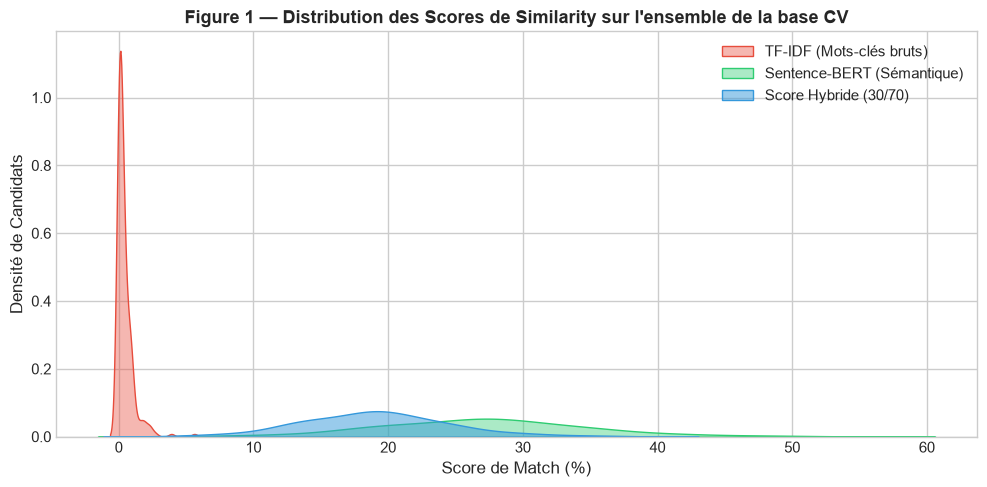

✅ Figure 1 enregistrée : c:\recrutement_ai\figures\fig1_distribution_scores.png


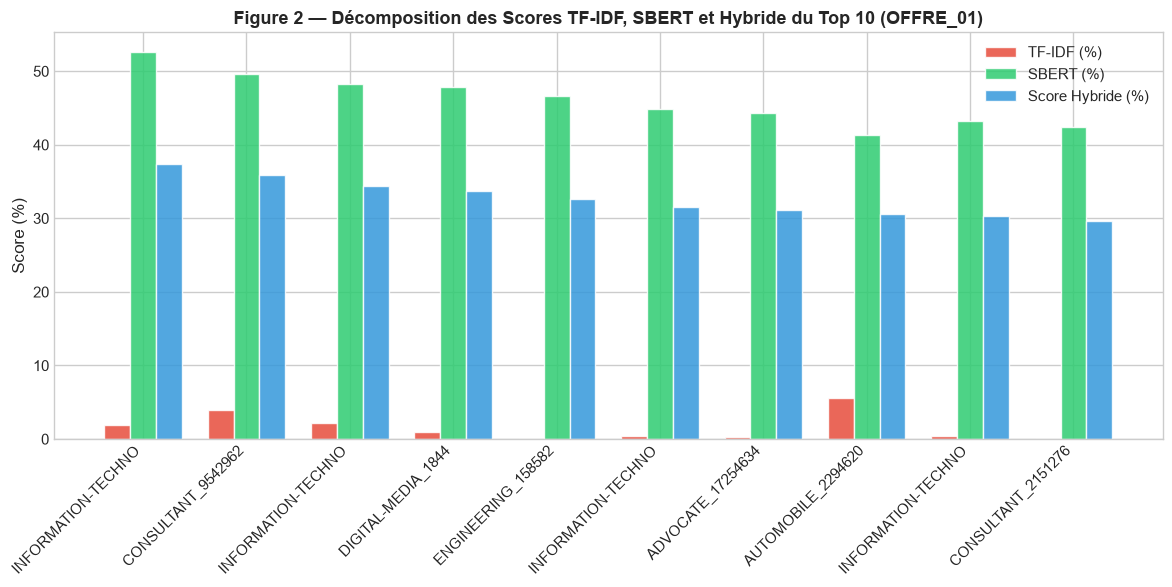

✅ Figure 2 enregistrée : c:\recrutement_ai\figures\fig2_top10_breakdown.png


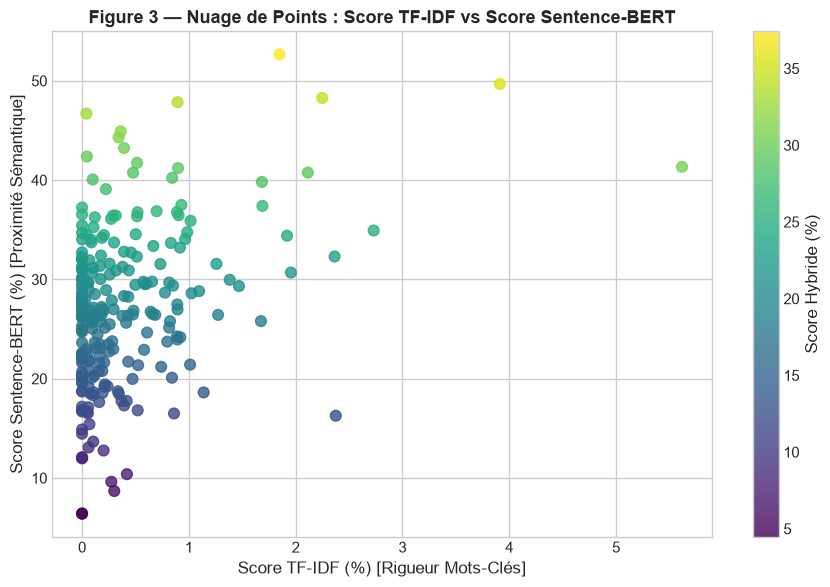

✅ Figure 3 enregistrée : c:\recrutement_ai\figures\fig3_scatter_tfidf_vs_sbert.png


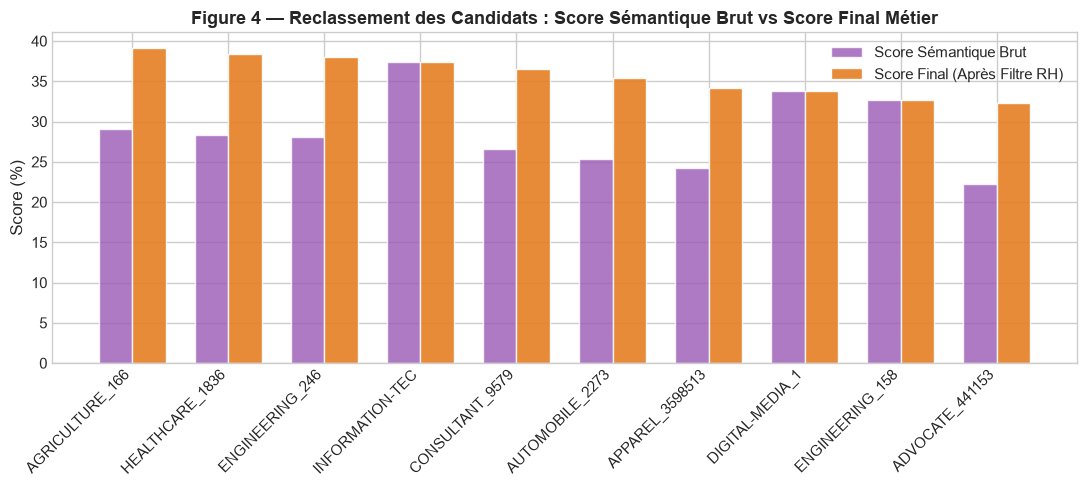

✅ Figure 4 enregistrée : c:\recrutement_ai\figures\fig4_impact_filtrage_metier.png


In [28]:
import os
import re
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# ------------------------------------------------------------------------------
# 1. CONFIGURATION DU STYLE GRAPHIQUE ET CHARGEMENT DES DONNÉES
# ------------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
BDD_SQLITE = os.path.join(BASE_DIR, "recrutement.db")
FIGURES_DIR = os.path.join(BASE_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

conn = sqlite3.connect(BDD_SQLITE)
df_candidats = pd.read_sql("SELECT * FROM candidats", conn)
df_offres = pd.read_sql("SELECT * FROM offres", conn)
conn.close()

sbert_model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

# Calcul du matching sur OFFRE_01 pour générer les figures
row_off = df_offres[df_offres['ID_Offre'] == 'OFFRE_01'].iloc[0]
texte_offre = (str(row_off['Description_Brute']) + " " + str(row_off['Competences_Exigees'])).lower()

corpus = [texte_offre] + df_candidats['Texte_Nettoye'].tolist()
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)
scores_tfidf = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:]).flatten() * 100

embedding_offre = sbert_model.encode([texte_offre])
embeddings_candidats = sbert_model.encode(df_candidats['Texte_Nettoye'].tolist(), show_progress_bar=False)
scores_sbert = cosine_similarity(embedding_offre, embeddings_candidats).flatten() * 100

scores_hybride = 0.3 * scores_tfidf + 0.7 * scores_sbert

df_res = df_candidats.copy()
df_res['Score_TFIDF'] = scores_tfidf
df_res['Score_SBERT'] = scores_sbert
df_res['Score_Hybride'] = scores_hybride

# ------------------------------------------------------------------------------
# FIGURE 1 : DISTRIBUTION COMPARATIVE DES SCORES (TF-IDF vs SBERT vs HYBRIDE)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(df_res['Score_TFIDF'], fill=True, color='#e74c3c', label='TF-IDF (Mots-clés bruts)', ax=ax, alpha=0.4)
sns.kdeplot(df_res['Score_SBERT'], fill=True, color='#2ecc71', label='Sentence-BERT (Sémantique)', ax=ax, alpha=0.4)
sns.kdeplot(df_res['Score_Hybride'], fill=True, color='#3498db', label='Score Hybride (30/70)', ax=ax, alpha=0.5)

ax.set_title("Figure 1 — Distribution des Scores de Similarity sur l'ensemble de la base CV", fontsize=13, fontweight='bold')
ax.set_xlabel("Score de Match (%)")
ax.set_ylabel("Densité de Candidats")
ax.legend(loc='upper right')
plt.tight_layout()
path_fig1 = os.path.join(FIGURES_DIR, "fig1_distribution_scores.png")
plt.savefig(path_fig1, dpi=300)
plt.show()
print(f"✅ Figure 1 enregistrée : {path_fig1}")

# ------------------------------------------------------------------------------
# FIGURE 2 : BREAKDOWN DES SCORES DU TOP 10 (BARPLOT GROUPÉ)
# ------------------------------------------------------------------------------
top10 = df_res.sort_values(by='Score_Hybride', ascending=False).head(10).copy()
top10['CV_ID'] = top10['Fichier_CV'].apply(lambda x: x.split('.')[0][:18])

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(top10))
width = 0.25

ax.bar(x - width, top10['Score_TFIDF'], width, label='TF-IDF (%)', color='#e74c3c', alpha=0.85)
ax.bar(x, top10['Score_SBERT'], width, label='SBERT (%)', color='#2ecc71', alpha=0.85)
ax.bar(x + width, top10['Score_Hybride'], width, label='Score Hybride (%)', color='#3498db', alpha=0.85)

ax.set_title("Figure 2 — Décomposition des Scores TF-IDF, SBERT et Hybride du Top 10 (OFFRE_01)", fontsize=13, fontweight='bold')
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(top10['CV_ID'], rotation=45, ha='right')
ax.legend()
plt.tight_layout()
path_fig2 = os.path.join(FIGURES_DIR, "fig2_top10_breakdown.png")
plt.savefig(path_fig2, dpi=300)
plt.show()
print(f"✅ Figure 2 enregistrée : {path_fig2}")

# ------------------------------------------------------------------------------
# FIGURE 3 : SCATTER PLOT TF-IDF VS SBERT (NUAGE DE POINTS)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(df_res['Score_TFIDF'], df_res['Score_SBERT'], c=df_res['Score_Hybride'], cmap='viridis', alpha=0.8, s=60)
cbar = plt.colorbar(scatter)
cbar.set_label('Score Hybride (%)')

ax.set_title("Figure 3 — Nuage de Points : Score TF-IDF vs Score Sentence-BERT", fontsize=13, fontweight='bold')
ax.set_xlabel("Score TF-IDF (%) [Rigueur Mots-Clés]")
ax.set_ylabel("Score Sentence-BERT (%) [Proximité Sémantique]")
plt.tight_layout()
path_fig3 = os.path.join(FIGURES_DIR, "fig3_scatter_tfidf_vs_sbert.png")
plt.savefig(path_fig3, dpi=300)
plt.show()
print(f"✅ Figure 3 enregistrée : {path_fig3}")

# ------------------------------------------------------------------------------
# FIGURE 4 : IMPACT DU FILTRAGE MÉTIER (SCORE SÉMANTIQUE VS SCORE FINAL)
# ------------------------------------------------------------------------------
def get_exp_num(t):
    t = str(t).lower()
    return 3 if any(k in t for k in ["sénior", "senior", "lead"]) else (1 if "junior" in t else 2)

def get_edu_num(t):
    t = str(t).lower()
    return 3 if any(k in t for k in ["master", "ingénieur"]) else (2 if "licence" in t else 1)

df_res['Num_Exp'] = df_res['Niveau_Experience'].apply(get_exp_num)
df_res['Num_Edu'] = df_res['Formation'].apply(get_edu_num)

def compute_soft(row):
    s = row['Score_Hybride']
    s += 5.0 if row['Num_Exp'] >= 3 else -10.0
    s += 5.0 if row['Num_Edu'] >= 3 else -5.0
    return np.clip(s, 0, 100)

df_res['Score_Final_Soft'] = df_res.apply(compute_soft, axis=1)
top10_soft = df_res.sort_values(by='Score_Final_Soft', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(top10_soft))
width = 0.35

ax.bar(x - width/2, top10_soft['Score_Hybride'], width, label='Score Sémantique Brut', color='#9b59b6', alpha=0.8)
ax.bar(x + width/2, top10_soft['Score_Final_Soft'], width, label='Score Final (Après Filtre RH)', color='#e67e22', alpha=0.9)

ax.set_title("Figure 4 — Reclassement des Candidats : Score Sémantique Brut vs Score Final Métier", fontsize=13, fontweight='bold')
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels([f.split('.')[0][:15] for f in top10_soft['Fichier_CV']], rotation=45, ha='right')
ax.legend()
plt.tight_layout()
path_fig4 = os.path.join(FIGURES_DIR, "fig4_impact_filtrage_metier.png")
plt.savefig(path_fig4, dpi=300)
plt.show()
print(f"✅ Figure 4 enregistrée : {path_fig4}")


# SAUVEGARDE DES FONCTIONS DE MATCHING

In [ ]:
import os

# Création du dossier src
os.makedirs("src", exist_ok=True)

# Contenu complet et documenté du module src/matching.py
code_matching = '''# ==============================================================================
# MODULE DE MATCHING CV - OFFRES D'EMPLOI (TF-IDF + SENTENCE-BERT + FILTRAGE MÉTIER)
# Projet de Mémoire : Moteur de Recommandation RH Intelligent
# ==============================================================================

import os
import re
import sqlite3
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# ------------------------------------------------------------------------------
# 1. PRÉTRAITEMENT TEXTUEL NLP
# ------------------------------------------------------------------------------
STOPWORDS = set([
    "le", "la", "les", "un", "une", "des", "du", "de", "en", "et", "est", "que", "qui", 
    "dans", "sur", "pour", "avec", "par", "au", "aux", "ce", "ces", "pas", "plus",
    "the", "a", "an", "and", "or", "in", "on", "at", "to", "for", "with", "by", "from",
    "of", "is", "are", "was", "were", "be", "been", "being", "have", "has", "had", "this"
])

def preprocess_text(text: str) -> str:
    """
    Nettoie le texte brut (passage en minuscules, suppression des e-mails, URLs,
    caractères spéciaux et stopwords).
    """
    if not isinstance(text, str) or not text.strip():
        return ""
    text_clean = text.lower()
    text_clean = re.sub(r'http\\S+|www\\S+|\\S+@\\S+', '', text_clean)
    text_clean = re.sub(r'[^a-zàâçéèêëîïôûùüÿñæœa-z]', ' ', text_clean)
    tokens = [w for w in text_clean.split() if w not in STOPWORDS and len(w) > 1]
    return " ".join(tokens)

# ------------------------------------------------------------------------------
# 2. EVALUATION NUMÉRIQUE DES CRITÈRES MÉTIER
# ------------------------------------------------------------------------------
def get_experience_level_numeric(text: str) -> int:
    """Convertit le niveau d'expérience textuel en échelle numérique (0 à 3)."""
    if not isinstance(text, str):
        return 0
    t = text.lower()
    if any(k in t for k in ["sénior", "senior", "lead", "10 ans", "15 ans", "18 ans", "20 ans", "7 ans", "13 ans"]):
        return 3
    elif any(k in t for k in ["intermédiaire", "confirmé", "5 ans", "3 ans", "4 ans", "2 ans"]):
        return 2
    elif any(k in t for k in ["junior", "débutant", "intern"]):
        return 1
    return 0

def get_education_level_numeric(text: str) -> int:
    """Convertit le niveau de formation textuel en échelle numérique (0 à 4)."""
    if not isinstance(text, str):
        return 0
    t = text.lower()
    if any(k in t for k in ["doctorat", "phd"]):
        return 4
    elif any(k in t for k in ["master", "ingénieur", "bac+5"]):
        return 3
    elif any(k in t for k in ["licence", "bachelor", "bac+3"]):
        return 2
    elif any(k in t for k in ["bts", "dut", "associate", "bac+2"]):
        return 1
    return 0

# ------------------------------------------------------------------------------
# 3. ACCÈS BASE DE DONNÉES ET CHARGEMENT DU MODÈLE SBERT
# ------------------------------------------------------------------------------
def load_database_data(db_path: str = "recrutement.db"):
    """Charge les tables 'candidats' et 'offres' depuis SQLite."""
    if not os.path.exists(db_path):
        raise FileNotFoundError(f"Base de données introuvable : {db_path}")
    conn = sqlite3.connect(db_path)
    df_cand = pd.read_sql("SELECT * FROM candidats", conn)
    df_off = pd.read_sql("SELECT * FROM offres", conn)
    conn.close()
    return df_cand, df_off

# Instance globale mise en cache pour éviter de recharger SBERT à chaque appel
_sbert_model = None

def get_sbert_model(model_name: str = 'paraphrase-multilingual-MiniLM-L12-v2'):
    """Charge et réutilise le modèle Sentence-BERT."""
    global _sbert_model
    if _sbert_model is None:
        _sbert_model = SentenceTransformer(model_name)
    return _sbert_model

# ------------------------------------------------------------------------------
# 4. MOTEUR DE MATCHING PRINCIPAL
# ------------------------------------------------------------------------------
def run_matching(id_offre: str, db_path: str = "recrutement.db", top_n: int = 10, strict_mode: bool = False):
    """
    Calcule le matching hybride (TF-IDF + SBERT) et applique les règles métier RH.
    
    Args:
        id_offre (str): Identifiant de l'offre (ex: 'OFFRE_01', 'OFFRE_02').
        db_path (str): Chemin d'accès à la base SQLite 'recrutement.db'.
        top_n (int): Nombre de candidats à retourner.
        strict_mode (bool): 
            - False: Soft Filter (Pondéré avec bonus/pénalités métier).
            - True: Hard Filter (Exclusion stricte des candidats sous-qualifiés).
            
    Returns:
        pd.DataFrame: Tableau structuré des candidats classés par pertinence.
    """
    df_cand, df_off = load_database_data(db_path)
    
    if 'Texte_Nettoye' not in df_cand.columns:
        df_cand['Texte_Nettoye'] = df_cand['Texte_Brut'].apply(preprocess_text)

    offre = df_off[df_off['ID_Offre'] == id_offre]
    if offre.empty:
        raise ValueError(f"L'offre '{id_offre}' n'existe pas dans la base de données.")

    row_off = offre.iloc[0]
    exp_exigee = row_off['Niveau_Experience_Exige']
    edu_exigee = row_off['Formation_Exigee']
    texte_offre = (str(row_off['Description_Brute']) + " " + str(row_off['Competences_Exigees'])).lower()

    num_exp_exigee = get_experience_level_numeric(exp_exigee)
    num_edu_exigee = get_education_level_numeric(edu_exigee)

    # A. Vectorisation TF-IDF (30%)
    corpus = [texte_offre] + df_cand['Texte_Nettoye'].tolist()
    tfidf_vectorizer = TfidfVectorizer()
    tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)
    scores_tfidf = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:]).flatten()

    # B. Vectorisation SBERT (70%)
    sbert_model = get_sbert_model()
    embedding_offre = sbert_model.encode([texte_offre])
    embeddings_candidats = sbert_model.encode(df_cand['Texte_Nettoye'].tolist(), show_progress_bar=False)
    scores_sbert = cosine_similarity(embedding_offre, embeddings_candidats).flatten()

    # C. Combinaison des scores NLP
    df_res = df_cand.copy()
    df_res['Score_TFIDF (%)'] = np.round(scores_tfidf * 100, 2)
    df_res['Score_SBERT (%)'] = np.round(scores_sbert * 100, 2)
    df_res['Score_Sémantique (%)'] = np.round(0.3 * df_res['Score_TFIDF (%)'] + 0.7 * df_res['Score_SBERT (%)'], 2)

    df_res['Num_Exp'] = df_res['Niveau_Experience'].apply(get_experience_level_numeric)
    df_res['Num_Edu'] = df_res['Formation'].apply(get_education_level_numeric)

    # D. Application de la logique métier (Hard Filter vs Soft Filter)
    if strict_mode:
        df_res = df_res[(df_res['Num_Exp'] >= num_exp_exigee) & (df_res['Num_Edu'] >= num_edu_exigee)]
        df_res['Score_Final (%)'] = df_res['Score_Sémantique (%)']
    else:
        def compute_business_score(row):
            score = row['Score_Sémantique (%)']
            if row['Num_Exp'] >= num_exp_exigee:
                score += 5.0
            elif 0 < row['Num_Exp'] < num_exp_exigee:
                score -= 10.0
                
            if row['Num_Edu'] >= num_edu_exigee:
                score += 5.0
            elif 0 < row['Num_Edu'] < num_edu_exigee:
                score -= 5.0
                
            return np.clip(np.round(score, 2), 0, 100)

        df_res['Score_Final (%)'] = df_res.apply(compute_business_score, axis=1)

    # E. Tri et préparation de la restitution
    df_res = df_res.sort_values(by='Score_Final (%)', ascending=False).reset_index(drop=True)
    df_res['Rang'] = df_res.index + 1

    cols_show = [
        'Rang', 'Fichier_CV', 'Prenom', 'Nom', 'Categorie_Poste', 
        'Niveau_Experience', 'Formation', 'Competences', 
        'Score_TFIDF (%)', 'Score_SBERT (%)', 'Score_Sémantique (%)', 'Score_Final (%)'
    ]
    return df_res[cols_show].head(top_n)

if __name__ == '__main__':
    print("🧪 Test d'exécution autonome du module 'src/matching.py'...")
    df_test = run_matching(id_offre='OFFRE_01', top_n=5, strict_mode=False)
    print(df_test.to_string())
'''

# Écriture du fichier dans src/matching.py
with open("src/matching.py", "w", encoding="utf-8") as f:
    f.write(code_matching)

print("✅ Module 'src/matching.py' créé et sauvegardé avec succès !")

✅ Module 'src/matching.py' créé et sauvegardé avec succès !


# evaluation --analyse comparative des ecarts TF-IDF vs Sentence- Bert

In [31]:
import os
import re
import sqlite3
import pandas as pd
import numpy as np
from scipy.stats import spearmanr, kendalltau
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# ------------------------------------------------------------------------------
# 1. RÉSOLUTION DYNAMIQUE DU CHEMIN DE LA BASE SQLITE
# ------------------------------------------------------------------------------
BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
BDD_SQLITE = os.path.join(BASE_DIR, "recrutement.db")

if not os.path.exists(BDD_SQLITE):
    raise FileNotFoundError(f"❌ La base SQLite est introuvable à l'adresse : {BDD_SQLITE}. Exécute d'abord le script d'initialisation de la BDD.")

conn = sqlite3.connect(BDD_SQLITE)
df_candidats = pd.read_sql("SELECT * FROM candidats", conn)
df_offres = pd.read_sql("SELECT * FROM offres", conn)
conn.close()

print(f"✅ Base chargée avec succès : {len(df_candidats)} candidats et {len(df_offres)} offres.")

# ------------------------------------------------------------------------------
# 2. EVALUATION STATISTIQUE DES ÉCARTS TF-IDF vs SBERT
# ------------------------------------------------------------------------------
sbert_model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

eval_results = []

for idx, row in df_offres.iterrows():
    id_off = row['ID_Offre']
    titre_off = row['Titre_Poste']
    texte_offre = (str(row['Description_Brute']) + " " + str(row['Competences_Exigees'])).lower()
    
    # Scores TF-IDF
    corpus = [texte_offre] + df_candidats['Texte_Nettoye'].tolist()
    tfidf_vec = TfidfVectorizer()
    tfidf_mat = tfidf_vec.fit_transform(corpus)
    scores_tfidf = cosine_similarity(tfidf_mat[0:1], tfidf_mat[1:]).flatten()
    
    # Scores SBERT
    emb_off = sbert_model.encode([texte_offre])
    emb_cand = sbert_model.encode(df_candidats['Texte_Nettoye'].tolist(), show_progress_bar=False)
    scores_sbert = cosine_similarity(emb_off, emb_cand).flatten()
    
    # Calcul des Rangs (1 = Premier)
    rank_tfidf = pd.Series(-scores_tfidf).rank(method='min').values
    rank_sbert = pd.Series(-scores_sbert).rank(method='min').values
    
    # Coefficients de Corrélation
    rho, _ = spearmanr(rank_tfidf, rank_sbert)
    tau, _ = kendalltau(rank_tfidf, rank_sbert)
    
    # Écarts de Rang
    mean_shift = np.mean(np.abs(rank_tfidf - rank_sbert))
    
    # Recouvrement Top 10
    top10_tfidf = set(np.argsort(-scores_tfidf)[:10])
    top10_sbert = set(np.argsort(-scores_sbert)[:10])
    overlap = len(top10_tfidf.intersection(top10_sbert)) / 10.0 * 100
    
    eval_results.append({
        'ID Offre': id_off,
        'Poste': titre_off,
        'Spearman Rho': round(rho, 4),
        'Kendall Tau': round(tau, 4),
        'Écart Moyen Rang': round(mean_shift, 1),
        'Recouvrement Top 10 (%)': round(overlap, 1)
    })

df_metrics = pd.DataFrame(eval_results)
print("\n" + "="*85)
print("📊 MATRICE D'ÉVALUATION COMPARATIVE DE LA PHASE 5 (CRISP-DM)")
print("="*85)
display(df_metrics)

✅ Base chargée avec succès : 240 candidats et 4 offres.


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1023.44it/s]



📊 MATRICE D'ÉVALUATION COMPARATIVE DE LA PHASE 5 (CRISP-DM)


,ID Offre,Poste,Spearman Rho,Kendall Tau,Écart Moyen Rang,Recouvrement Top 10 (%)
0,OFFRE_01,Data Scientist Senior,0.2828,0.1967,61.9,30.0
1,OFFRE_02,Développeur Fullstack Python / React,0.1337,0.1061,89.3,40.0
2,OFFRE_03,Responsable Ressources Humaines & Recrutement,0.2525,0.1711,67.0,0.0
3,OFFRE_04,Analyste Financier & Comptable,0.3505,0.2489,57.1,50.0


In [32]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Configuration de la figure (haute résolution 300 DPI)
fig, ax = plt.subplots(figsize=(15, 11), dpi=300)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

# Palette de couleurs harmonieuse
font_family = 'DejaVu Sans'
title_color = '#1E3A8A'      # Bleu Marine Foncé

box_bg_input = '#E0F2FE'     # Bleu Ciel
box_bg_proc = '#FEF3C7'      # Jaune Ambré
box_bg_db = '#DCFCE7'        # Vert Émeraude
box_bg_engine = '#F3E8FF'    # Violet
box_bg_out = '#FCE7F3'       # Rose / Dashboard

border_color = '#334155'     # Gris Ardoise

def draw_box(ax, x, y, width, height, title, subtitle, bg_color, border_color='#334155'):
    """Dessine un bloc arrondi avec titre et sous-titre."""
    box = patches.FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.5,rounding_size=1.5",
        ec=border_color, fc=bg_color, lw=1.5
    )
    ax.add_patch(box)
    
    # Titre du bloc
    ax.text(x + width/2, y + height/2 + (1.6 if subtitle else 0), title,
            ha='center', va='center', fontsize=11, fontweight='bold', color='#0F172A', family=font_family)
    # Sous-titre / Détails
    if subtitle:
        ax.text(x + width/2, y + height/2 - 2.2, subtitle,
                ha='center', va='center', fontsize=8.5, color='#475569', family=font_family, style='italic', linespacing=1.3)

def draw_arrow(ax, x1, y1, x2, y2, label='', label_pos=(0.5, 0.5), ha='center', va='bottom'):
    """Trace une flèche orientée avec étiquette."""
    ax.annotate(
        '', xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="-|>", color='#334155', lw=2, mutation_scale=15)
    )
    if label:
        lx = x1 + (x2 - x1) * label_pos[0]
        ly = y1 + (y2 - y1) * label_pos[1]
        ax.text(lx, ly, label, ha=ha, va=va, fontsize=8, color='#1E293B', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.8))

# Titre Principal
plt.text(50, 96, "PIPELINE TECHNIQUE DU SYSTÈME RECRUTEMENT AI", ha='center', va='center',
         fontsize=16, fontweight='bold', color=title_color)
plt.text(50, 92.5, "De l'extraction textuelle au Matching Hybride (TF-IDF + SBERT) sous Streamlit", ha='center', va='center',
         fontsize=10.5, color='#475569', style='italic')

# 1. Bloc Entrées
draw_box(ax, 4, 76, 24, 10, "1. CVs PDF (240 dossiers)", "Corpus non structuré (Kaggle)", box_bg_input)
draw_box(ax, 4, 58, 24, 10, "2. Fiches de Poste (4 offres)", "Offres étalons (dataset_offres.csv)", box_bg_input)

# Flèches Entrées -> Extraction
draw_arrow(ax, 28, 81, 36, 81, "Fichiers PDF", label_pos=(0.5, 0.5), va='bottom')
draw_arrow(ax, 28, 63, 36, 68)

# 2. Bloc Pipeline NLP
draw_box(ax, 36, 62, 28, 24, "3. Pipeline Extraction & NLP", 
         "• PyMuPDF (fitz) : Texte Brut\n• spaCy : Minuscules, Regex\n• Nettoyage & Lemmatisation\n• Génération du Texte Nettoyé", 
         box_bg_proc)

# Flèche Pipeline NLP -> Base SQLite
draw_arrow(ax, 50, 62, 50, 52, "Données Structurées", label_pos=(0.5, 0.5), ha='left', va='center')

# 3. Bloc Base SQLite
draw_box(ax, 34, 38, 32, 14, "4. Base de Données SQLite", "Table 'candidats' & 'offres'\n(recrutement.db)", box_bg_db)

# Flèches SQLite -> Volets de Matching
draw_arrow(ax, 34, 45, 26, 38, "Texte Nettoyé", label_pos=(0.4, 0.4), ha='right')
draw_arrow(ax, 66, 45, 74, 38, "Texte Brut / Contexte", label_pos=(0.4, 0.4), ha='left')

# 4. Moteur de Matching Hybride
draw_box(ax, 4, 26, 26, 12, "5a. Volet Lexical (TF-IDF)", "Scikit-Learn + Cosine Similarity\n(Validation Mots-Clés Stricts)", box_bg_engine)
draw_box(ax, 70, 26, 26, 12, "5b. Volet Sémantique (SBERT)", "paraphrase-multilingual-MiniLM-L12-v2\n(Embeddings & Synonymie)", box_bg_engine)

# Convergence vers Fusion des Scores
draw_arrow(ax, 17, 26, 34, 14)
draw_arrow(ax, 83, 26, 66, 14)

# Bloc Fusion
draw_box(ax, 34, 6, 32, 12, "6. Fusion Hybride des Scores", "Score Combiné Pondéré (Alpha)\nS_final = a·S_tfidf + (1-a)·S_sbert", box_bg_engine)

# Flèche Fusion -> Dashboard
draw_arrow(ax, 66, 12, 75, 12, "Scores & Classements", label_pos=(0.5, 0.5), va='bottom')

# 5. Bloc Interface Utilisateur
draw_box(ax, 75, 6, 21, 12, "7. Interface Streamlit", "Dashboard (app.py)\nParadigme Human-in-the-Loop", box_bg_out)

# Export de l'image
plt.tight_layout()
plt.savefig("pipeline_recrutement_ai.png", dpi=300, bbox_inches='tight')
plt.close()

print("Figure générée avec succès : pipeline_recrutement_ai.png")

Figure générée avec succès : pipeline_recrutement_ai.png


In [33]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Configuration de la figure haute résolution (300 DPI)
fig, ax = plt.subplots(figsize=(15, 12), dpi=300)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

font_family = 'DejaVu Sans'
title_color = '#1E3A8A' # Bleu Marine

# Couleurs de fond des conteneurs par couche
bg_tier1 = '#FCE7F3'  # Rose pastel (Couche Présentation Streamlit)
bg_tier2 = '#FEF3C7'  # Ambre pastel (Couche Traitement & ML Engine)
bg_tier3 = '#DCFCE7'  # Vert émeraude (Couche Données & SQLite)

# Couleurs spécifiques des sous-composants
box_sub_engine = '#F3E8FF' # Violet clair
box_sub_nlp = '#E0F2FE'    # Bleu clair

def draw_layer_container(ax, x, y, width, height, title, bg_color, border_color='#1E293B'):
    """Dessine le cadre d'une couche globale de l'architecture 3-tier."""
    box = patches.FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.5,rounding_size=2.0",
        ec=border_color, fc=bg_color, lw=2.0, alpha=0.9
    )
    ax.add_patch(box)
    ax.text(x + 2, y + height - 3.5, title, fontsize=12, fontweight='bold', color='#0F172A', family=font_family)

def draw_box(ax, x, y, width, height, title, subtitle, bg_color='#FFFFFF', border_color='#334155'):
    """Dessine un sous-bloc fonctionnel à l'intérieur d'une couche."""
    box = patches.FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.4,rounding_size=1.2",
        ec=border_color, fc=bg_color, lw=1.2
    )
    ax.add_patch(box)
    
    ax.text(x + width/2, y + height/2 + (1.5 if subtitle else 0), title,
            ha='center', va='center', fontsize=10.5, fontweight='bold', color='#0F172A', family=font_family)
    if subtitle:
        ax.text(x + width/2, y + height/2 - 2.0, subtitle,
                ha='center', va='center', fontsize=8.5, color='#334155', family=font_family, style='italic', linespacing=1.3)

def draw_arrow(ax, x1, y1, x2, y2, label=''):
    """Trace une flèche bidirectionnelle entre les couches avec une étiquette."""
    ax.annotate(
        '', xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="<|-|>", color='#1E293B', lw=2, mutation_scale=15)
    )
    if label:
        mid_x = (x1 + x2) / 2
        mid_y = (y1 + y2) / 2
        ax.text(mid_x + 1.5, mid_y, label, ha='left', va='center', fontsize=8.5, fontweight='bold', color='#1E293B',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.9))

# Titre Principal
plt.text(50, 96.5, "ARCHITECTURE DE LA SOLUTION RECRUTEMENT AI", ha='center', va='center',
         fontsize=16, fontweight='bold', color=title_color)
plt.text(50, 93.5, "Modèle à Trois Tiers (3-Tier Architecture) : Présentation, Traitement & Données", ha='center', va='center',
         fontsize=10.5, color='#475569', style='italic')

# TIER 1: COUCHE PRÉSENTATION
draw_layer_container(ax, 5, 67, 90, 23, "COUCHE 1 : PRÉSENTATION (INTERFACE UTILISATEUR)", bg_tier1)
draw_box(ax, 8, 70, 26, 14, "Module d'Import & Saisie", "• Téléversement CVs (PDF)\n• Saisie / Import Fiche de Poste\n• Drag-and-Drop dynamique")
draw_box(ax, 37, 70, 26, 14, "Contrôle & Paramétrage", "• Curseur de pondération α\n• Filtres Métier / Expérience\n• Mode Démo / Mode Temps Réel")
draw_box(ax, 66, 70, 26, 14, "Restitution & Dashboard", "• Ranking RH interactif\n• Graphiques comparatifs Plotly\n• Explicabilité des scores")

# TIER 2: COUCHE TRAITEMENT & ML ENGINE
draw_layer_container(ax, 5, 34, 90, 25, "COUCHE 2 : TRAITEMENT & MOTEUR DE MATCHING HYBRIDE (LOGIQUE MÉTIER)", bg_tier2)
draw_box(ax, 8, 37, 26, 16, "Parsing & Pipeline NLP", "• PyMuPDF (fitz) : Extr. Texte\n• spaCy : Nettoyage & Regex\n• Lemmatisation & Stopwords", bg_color=box_sub_nlp)
draw_box(ax, 37, 37, 26, 16, "Moteur Hybride (src/)", "• TF-IDF (Scikit-Learn)\n• SBERT (MiniLM-L12-v2)\n• Fusion: α·S_tfidf + (1-α)·S_sbert", bg_color=box_sub_engine)
draw_box(ax, 66, 37, 26, 16, "Module Explicabilité", "• Décomposition S_tfidf & S_sbert\n• Extraction compétences clés\n• Paradigme Human-in-the-Loop")

# TIER 3: COUCHE DONNÉES & PERSISTANCE
draw_layer_container(ax, 5, 6, 90, 20, "COUCHE 3 : DONNÉES & PERSISTANCE (PERSISTENCE LAYER)", bg_tier3)
draw_box(ax, 10, 9, 36, 12, "Base de Données SQLite (recrutement.db)", "• Table 'candidats' (240 profils structurés)\n• Table 'offres' (4 fiches de poste étalons)")
draw_box(ax, 54, 9, 36, 12, "Système de Fichiers Local", "• Répertoire /data (CVs PDF issus de Kaggle)\n• Fichier 'dataset_offres.csv'")

# Flèches de communication inter-couches
draw_arrow(ax, 21, 67, 21, 59, "Requêtes & Data Stream")
draw_arrow(ax, 80, 59, 80, 67, "Scores & Dataframes")
draw_arrow(ax, 28, 34, 28, 26, "SQL Read / Write")
draw_arrow(ax, 72, 26, 72, 34, "Chargement Données")

# Sauvegarde du fichier
plt.tight_layout()
plt.savefig("architecture_3_tiers_recrutement_ai.png", dpi=300, bbox_inches='tight')
plt.close()

print("Figure générée avec succès : architecture_3_tiers_recrutement_ai.png")

Figure générée avec succès : architecture_3_tiers_recrutement_ai.png


In [34]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Configuration de la figure haute résolution (300 DPI)
fig, ax = plt.subplots(figsize=(16, 9.5), dpi=300)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

font_family = 'DejaVu Sans'
title_color = '#1E3A8A'

# Palette de couleurs Merise / UML
candidat_hdr_bg = '#0284C7'    # Bleu Ciel
candidat_body_bg = '#F0F9FF'   # Fond Bleu Clair
offre_hdr_bg = '#16A34A'       # Vert Émeraude
offre_body_bg = '#F0FDF4'      # Fond Vert Clair
rel_hdr_bg = '#9333EA'         # Violet
rel_body_bg = '#FAF5FF'        # Fond Violet Clair
border_col = '#334155'         # Gris Ardoise

def draw_entity(ax, x, y, width, height_hdr, height_body, title, attributes, hdr_bg, body_bg):
    """Dessine une entité Merise avec son en-tête et sa liste d'attributs."""
    body = patches.FancyBboxPatch(
        (x, y), width, height_body,
        boxstyle="round,pad=0.2,rounding_size=1.0",
        ec=border_col, fc=body_bg, lw=1.5
    )
    ax.add_patch(body)
    
    hdr = patches.FancyBboxPatch(
        (x, y + height_body - height_hdr), width, height_hdr,
        boxstyle="round,pad=0.2,rounding_size=1.0",
        ec=border_col, fc=hdr_bg, lw=1.5
    )
    ax.add_patch(hdr)
    
    ax.text(x + width/2, y + height_body - height_hdr/2, title,
            ha='center', va='center', fontsize=12, fontweight='bold', color='white', family=font_family)
    
    start_y = y + height_body - height_hdr - 3.5
    for i, attr in enumerate(attributes):
        is_pk = attr.startswith('#') or attr.startswith('*')
        font_weight = 'bold' if is_pk else 'normal'
        ax.text(x + 2.5, start_y - (i * 3.8), attr,
                ha='left', va='center', fontsize=9.5, fontweight=font_weight, color='#0F172A', family=font_family)

def draw_relationship(ax, x, y, width, height, title, attributes, hdr_bg, body_bg):
    """Dessine l'association (relation) Merise avec ses attributs portés."""
    rel_box = patches.FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.4,rounding_size=2.0",
        ec=border_col, fc=body_bg, lw=1.5
    )
    ax.add_patch(rel_box)
    
    ax.text(x + width/2, y + height - 3.5, title,
            ha='center', va='center', fontsize=11, fontweight='bold', color=hdr_bg, family=font_family)
    
    ax.plot([x + 2, x + width - 2], [y + height - 6, y + height - 6], color=border_col, lw=1, linestyle='--')
    
    start_y = y + height - 9.0
    for i, attr in enumerate(attributes):
        ax.text(x + width/2, start_y - (i * 3.5), attr,
                ha='center', va='center', fontsize=9, color='#334155', family=font_family, style='italic')

# En-tête de la Figure
plt.text(50, 96, "Figure 9 : Modèle Conceptuel de Données (MCD)", ha='center', va='center',
         fontsize=15, fontweight='bold', color=title_color)
plt.text(50, 92.5, "Structure entités-relations et cardinalités du système RECRUTEMENT AI", ha='center', va='center',
         fontsize=10.5, color='#475569', style='italic')

# 1. ENTITÉ CANDIDAT
attrs_candidat = [
    "# id_candidat (PK)",
    "  fichier_cv",
    "  prenom",
    "  nom",
    "  categorie_poste",
    "  niveau_experience",
    "  formation",
    "  competences",
    "  texte_brut",
    "  texte_nettoye"
]
draw_entity(ax, 6, 22, 28, 6.5, 60, "CANDIDAT", attrs_candidat, candidat_hdr_bg, candidat_body_bg)

# 2. ENTITÉ OFFRE D'EMPLOI
attrs_offre = [
    "# id_offre (PK)",
    "  intitule_poste",
    "  categorie_metier",
    "  experience_exigee",
    "  formation_exigee",
    "  competences_cles",
    "  texte_brut",
    "  texte_nettoye"
]
draw_entity(ax, 66, 28, 28, 6.5, 54, "OFFRE_D_EMPLOI", attrs_offre, offre_hdr_bg, offre_body_bg)

# 3. ASSOCIATION / RELATIONSHIP (EVALUATION / MATCHING)
attrs_rel = [
    "score_tfidf (%)",
    "score_sbert (%)",
    "score_final (%)",
    "date_matching"
]
draw_relationship(ax, 38, 43, 24, 22, "EST_EVALUÉ_PAR", attrs_rel, rel_hdr_bg, rel_body_bg)

# Cardinalités et Lignes d'association
ax.plot([34, 38], [54, 54], color=border_col, lw=2)
ax.text(35.5, 56.5, "1,N", ha='center', va='center', fontsize=11, fontweight='bold', color='#1E293B',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#CBD5E1', lw=1))

ax.plot([62, 66], [54, 54], color=border_col, lw=2)
ax.text(64.2, 56.5, "0,N", ha='center', va='center', fontsize=11, fontweight='bold', color='#1E293B',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#CBD5E1', lw=1))

# Légende et explications bas de page
note_text = "Notes : Cardinalité (1,N) : Un candidat est évalué sur au moins 1 offre (ou N offres).\n" \
            "         Cardinalité (0,N) : Une offre d'emploi est comparée à 0 ou N candidats du vivier."
ax.text(50, 10, note_text, ha='center', va='center', fontsize=9, color='#475569', style='italic',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#F8FAFC', edgecolor='#E2E8F0', lw=1))

plt.tight_layout()
plt.savefig("figure9_mcd_offre_candidat.png", dpi=300, bbox_inches='tight')
plt.close()

print("Figure 9 générée avec succès : figure9_mcd_offre_candidat.png")

Figure 9 générée avec succès : figure9_mcd_offre_candidat.png
